In [1]:
'''
comparing eff and inference cutoffs for various quantities
'''

'\ncomparing eff and inference cutoffs for various quantities\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib

In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
df_inference = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_inf_dups")

In [3]:
base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"

# df = pd.read_csv(base_path+"df_snr_sobel_eff")

In [69]:
df_eff.to_csv(base_path+"df_eff_normsob")

In [4]:
df_eff=pd.read_csv(base_path+"df_eff_normsob")

In [ ]:
df_eff = rff.add_normsobel_stuff(df, eff=True)

In [5]:
def rmdups(df, eff, size=False):
    if size==True:
        df.sort_values("detection_size", inplace=True)
        if eff==True:
            return df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")
        else:
            return df.drop_duplicates(subset=["filename", 
                                          "quad",
                                          "closest_x", "closest_y", "noise_local_new","height_new"], keep="last")
    if eff==True:
        df.sort_values("snr_local", inplace=True)
        # snr_local  
        return df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")
    else:
        df.sort_values("snr_local_new", inplace=True)
        return df.drdetsizelimduplicates(subset=["filename", 
                                          "quad",
                                          "closest_x", "closest_y", "noise_local_new","height_new"], keep="last")

In [15]:
df_inference.iloc[0]

Unnamed: 0.7                                                                 0
Unnamed: 0.6                                                                 0
Unnamed: 0.5                                                                 0
Unnamed: 0.4                                                                 0
Unnamed: 0.3                                                                 0
Unnamed: 0.2                                                                 0
Unnamed: 0.1                                                                 0
Unnamed: 0                                                                   0
filename                              ztf_20221020297847_000449_zr_c15_x_0006.
quad                                                                         4
type                                                                       pos
row_from_nn                                                               22.5
col_from_nn                                         

In [31]:
df_eff_nodups = rmdups(df_eff, eff=True)

In [18]:
len(df_inference) - len(rmdups(df_inference, eff=False))

226957

In [12]:
# df_inf_nodups = rmdups(df_inference, eff=False)

In [9]:
df_inf_nodups = df_inference[df_inference['is_smaller_dup']==0]

In [ ]:
np.min(df_eff_nodups[quant])

2.4701130390167236

The efficiency drops by 0.0 % with cutoff at 2.47.
The number of candidates reduces by 0.1% from 667818 to 667137.
The efficiency drops by 0.5 % with cutoff at 3.
The number of candidates reduces by 0.1% from 667818 to 666980.
The efficiency drops by 5.7 % with cutoff at 5.
The number of candidates reduces by 0.2% from 667818 to 666477.
The efficiency drops by 29.9 % with cutoff at 10.
The number of candidates reduces by 0.9% from 667818 to 662069.


Text(0.5, 0.98, 'sobel_norm_stdv_rat')

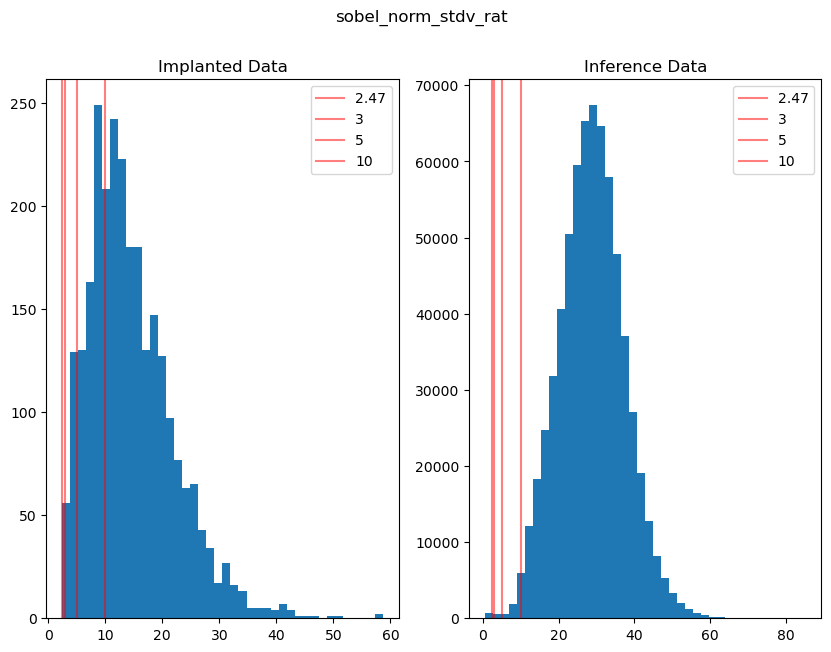

In [96]:
quant = "sobel_norm_stdv_rat"
cutoff_options = [2.47,3, 5,10]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(df_eff_nodups[quant], bins=bins)
ax[1].hist(df_inf_nodups[quant], bins=bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups[df_eff_nodups[quant]<option])/len(df_eff_nodups):.1f} % with cutoff at {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups[df_inf_nodups[quant]<option])/len(df_inf_nodups):.1f}% from {len(df_inf_nodups)} to {len(df_inf_nodups[df_inf_nodups[quant]>option])}.")
    for axis in ax:
        axis.axvline(option, label=option, c="r", alpha=.5)
        axis.legend()
fig.suptitle(quant)

The efficiency drops by 0.0 % with cutoff at 2.47.
The number of candidates reduces by 0.1% from 667818 to 667131.
The efficiency drops by 0.3 % with cutoff at 3.
The number of candidates reduces by 0.1% from 667818 to 666970.
The efficiency drops by 5.8 % with cutoff at 5.
The number of candidates reduces by 0.2% from 667818 to 666474.
The efficiency drops by 30.0 % with cutoff at 10.
The number of candidates reduces by 0.9% from 667818 to 661990.


Text(0.5, 0.98, 'sobel_norm_stdv_rat')

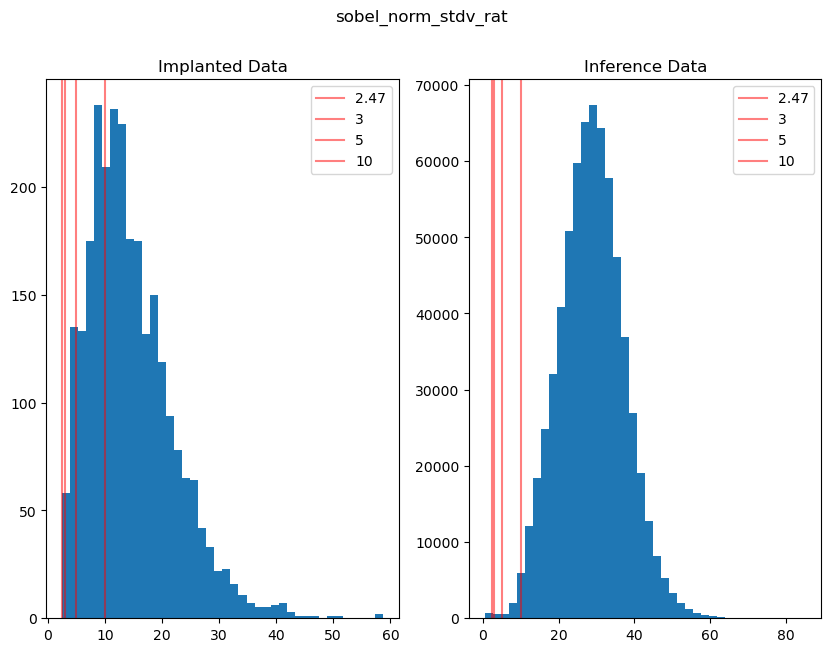

In [76]:
#with detection size duplicate drop
quant = "sobel_norm_stdv_rat"
cutoff_options = [2.47,3, 5,10]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(df_eff_nodups_ds[quant], bins=bins)
ax[1].hist(df_inf_nodups_ds[quant], bins=bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups_ds[df_eff_nodups_ds[quant]<option])/len(df_eff_nodups_ds):.1f} % with cutoff at {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups_ds[df_inf_nodups_ds[quant]<option])/len(df_inf_nodups_ds):.1f}% from {len(df_inf_nodups_ds)} to {len(df_inf_nodups_ds[df_inf_nodups_ds[quant]>option])}.")
    for axis in ax:
        axis.axvline(option, label=option, c="r", alpha=.5)
        axis.legend()
fig.suptitle(quant)

The efficiency drops by 0.0 % with cutoff < 1.
The number of candidates reduces by 0.0% from 667818 to 667818.
The efficiency drops by 1.4 % with cutoff < 2.
The number of candidates reduces by 10.1% from 667818 to 600694.
The efficiency drops by 4.5 % with cutoff < 5.
The number of candidates reduces by 41.0% from 667818 to 393795.


Text(0.5, 0.98, 'detection_size')

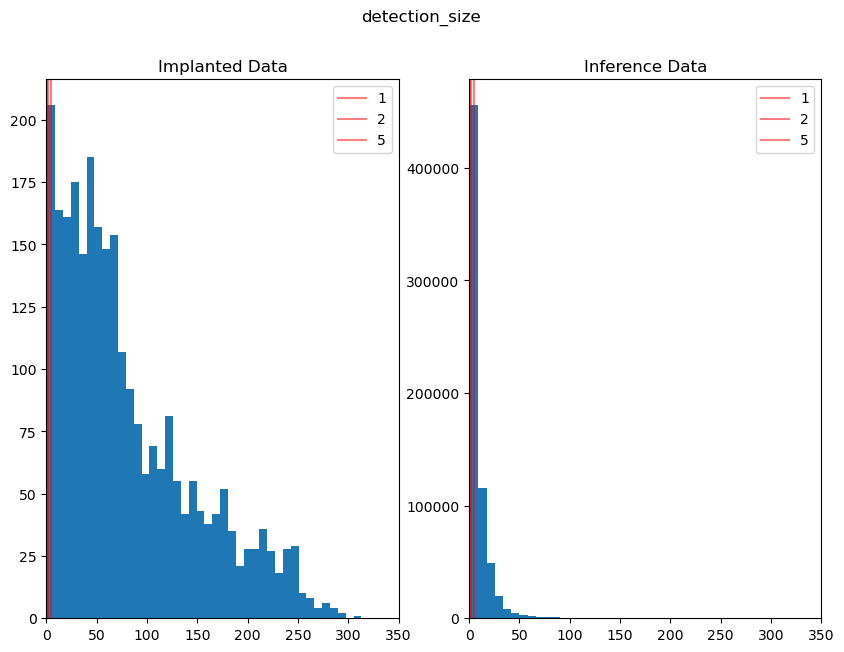

In [61]:
#new
df_eff_nodups_ds = rmdups(df_eff, eff=True, size=True)
df_inf_nodups_ds = rmdups(df_inference, eff=False,size=True)

quant = "detection_size"
cutoff_options = [1,2,5]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(df_eff_nodups_ds[quant], bins=bins)
ax[1].hist(df_inf_nodups_ds[quant], bins=20*bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups_ds[df_eff_nodups_ds[quant]<option])/len(df_eff_nodups_ds):.1f} % with cutoff < {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups_ds[df_inf_nodups_ds[quant]<option])/len(df_inf_nodups_ds):.1f}% from {len(df_inf_nodups_ds)} to {len(df_inf_nodups_ds[df_inf_nodups_ds[quant]>=option])}.")
    for axis in ax:
        axis.axvline(option, label=option, c="r", alpha=.5)
        axis.legend()
        axis.set_xlim(0,350)
fig.suptitle(quant)


In [55]:
(667818-495999)/667818

0.257284170237999

In [57]:
option

5

In [61]:
len(df_inf_nodups[df_inf_nodups[quant]<5])/len(df_inf_nodups)

0.48472488013201204

In [60]:
100len(df_inf_nodups[df_inf_nodups[quant]>5])

295750

The efficiency drops by 0.2 % with cutoff < 0.1.
The number of candidates reduces by 14.3% from 667818 to 572511.
The efficiency drops by 8.6 % with cutoff < 0.5.
The number of candidates reduces by 89.7% from 667818 to 68576.
The efficiency drops by 14.8 % with cutoff < 1.
The number of candidates reduces by 98.5% from 667818 to 10306.


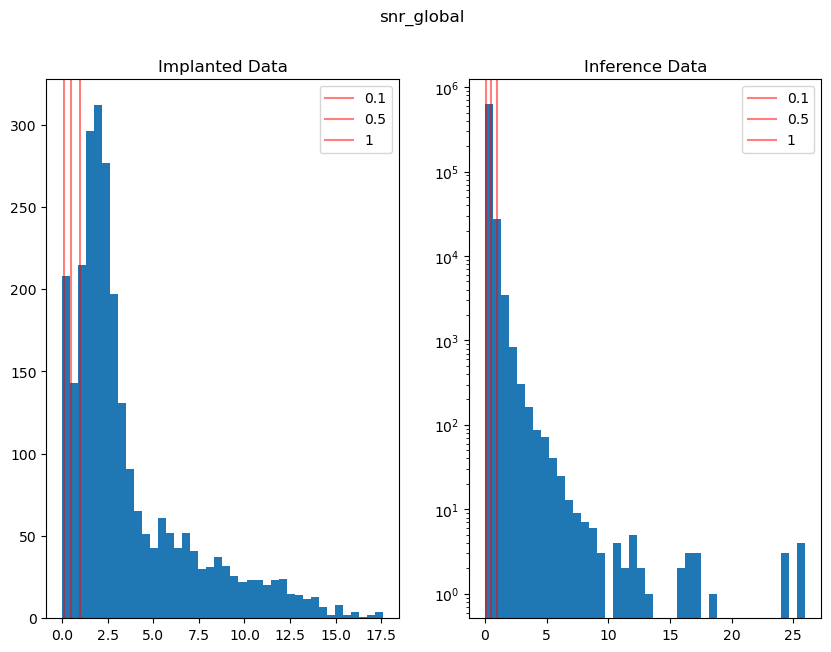

In [94]:
quant = "snr_global"
quant2 = "snr_global_new"
cutoff_options = [0.1,0.5,1]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(df_eff_nodups[quant], bins=bins)
ax[1].hist(df_inf_nodups[quant2], bins=bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups[df_eff_nodups[quant]<option])/len(df_eff_nodups):.1f} % with cutoff < {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups[df_inf_nodups[quant2]<option])/len(df_inf_nodups):.1f}% from {len(df_inf_nodups)} to {len(df_inf_nodups[df_inf_nodups[quant2]>=option])}.")
    for axis in ax:
        axis.axvline(option, label=option,c="r", alpha=.5)
        axis.legend()
        
fig.suptitle(quant)
ax[1].set_yscale("log")

The efficiency drops by 0.1 % with cutoff < 0.1.
The number of candidates reduces by 12.5% from 667818 to 584029.
The efficiency drops by 8.0 % with cutoff < 0.5.
The number of candidates reduces by 87.9% from 667818 to 81041.
The efficiency drops by 13.9 % with cutoff < 1.
The number of candidates reduces by 98.1% from 667818 to 12773.


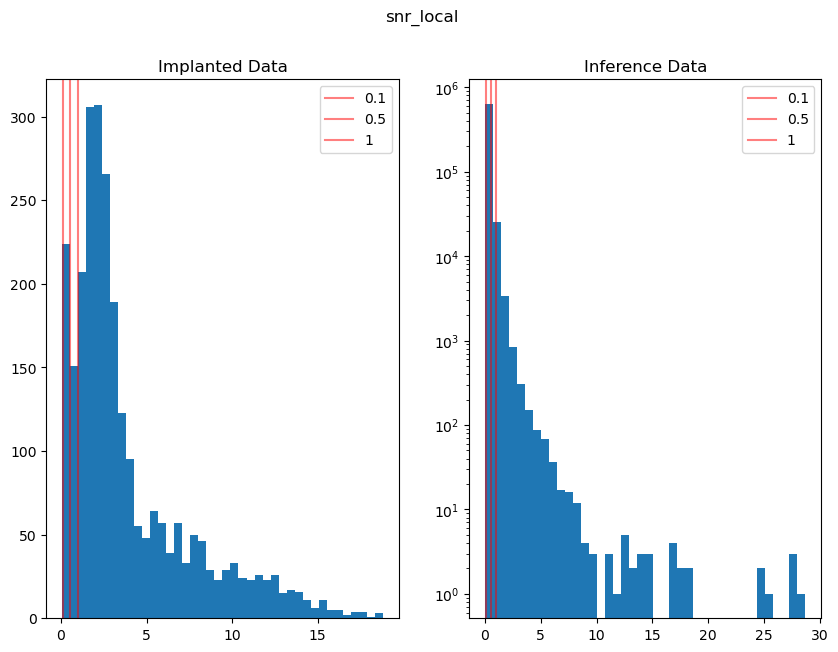

In [93]:
quant = "snr_local"
quant2 = "snr_local_new"
cutoff_options = [0.1,0.5,1]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(df_eff_nodups[quant], bins=bins)
ax[1].hist(df_inf_nodups[quant2], bins=bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups[df_eff_nodups[quant]<option])/len(df_eff_nodups):.1f} % with cutoff < {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups[df_inf_nodups[quant2]<option])/len(df_inf_nodups):.1f}% from {len(df_inf_nodups)} to {len(df_inf_nodups[df_inf_nodups[quant2]>=option])}.")
    for axis in ax:
        axis.axvline(option, label=option,c="r", alpha=.5)
        axis.legend()
        
fig.suptitle(quant)
ax[1].set_yscale("log")

In [76]:
matched = pd.read_csv(base_path+"matched")

The efficiency drops by 9.2 % with cutoff <= 5.
The number of candidates reduces by 27.2% from 667818 to 486275.
The efficiency drops by 2.1 % with cutoff <= 10.
The number of candidates reduces by 0.0% from 667818 to 667818.
(it was already cut at 10)


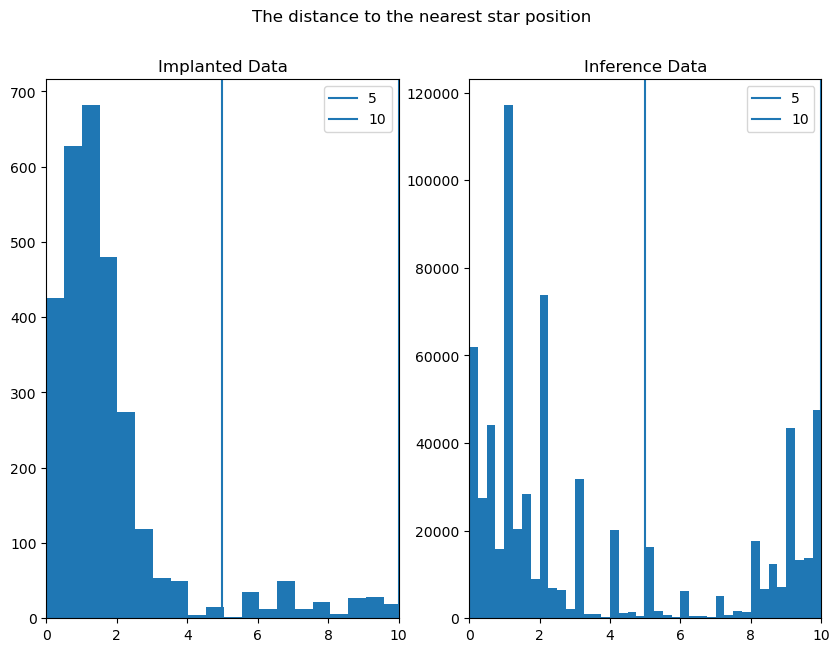

In [85]:
quant = "Diff"
quant2 = "Diff"
cutoff_options = [5, 10]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(np.abs(matched[quant]), bins=10*bins)
ax[1].hist(np.abs(df_inf_nodups[quant2]), bins=bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(matched[np.abs(matched[quant])>option])/len(matched):.1f} % with cutoff <= {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups[np.abs(df_inf_nodups[quant2])>option])/len(df_inf_nodups):.1f}% from {len(df_inf_nodups)} to {len(df_inf_nodups[np.abs(df_inf_nodups[quant2])<=option])}.")
    for axis in ax:
        axis.axvline(option, label=option)
        axis.legend()
        axis.set_xlim(0,10)
fig.suptitle("The distance to the nearest star position")
print("(it was already cut at 10)")

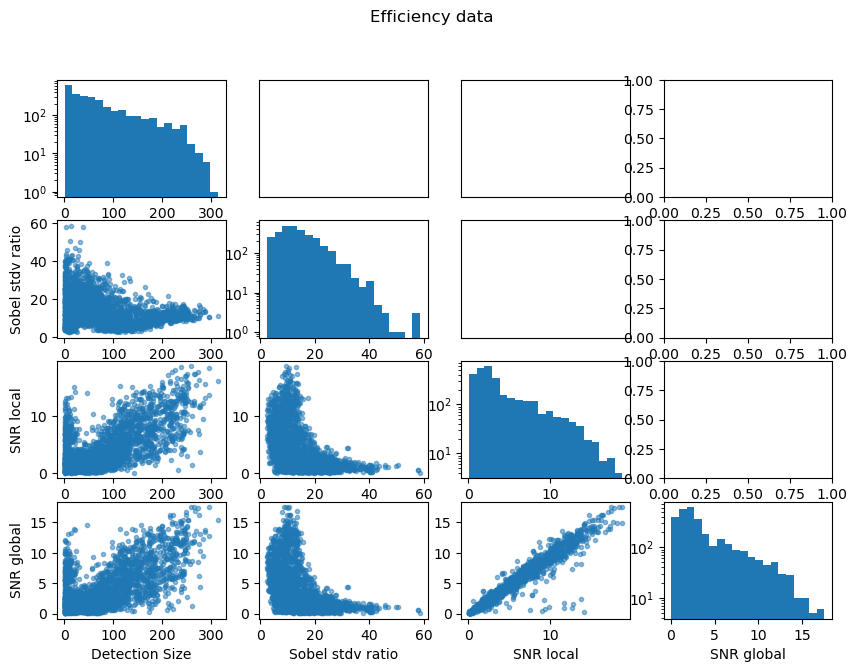

In [181]:
df = df_eff_nodups
fig, ax = plt.subplots(4,4)
size=4

fig.suptitle("Efficiency data")

ax[0,0].hist(df["detection_size"], bins=20)
ax[1,0].plot(df["detection_size"], df["sobel_norm_stdv_rat"],'.', alpha=.5)
ax[2,0].plot(df["detection_size"], df["snr_local"],'.', alpha=.5)


# ax[0,0].hist(df["detection_size"])
ax[1,1].hist(df["sobel_norm_stdv_rat"], bins=20)
ax[2,1].plot(df["sobel_norm_stdv_rat"], df["snr_local"],'.', alpha=.5)

ax[2,2].hist(df["snr_local"], bins=20)


ax[size-1,0].set_xlabel("Detection Size")
ax[1,0].set_ylabel("Sobel stdv ratio")
ax[2,0].set_ylabel("SNR local")
ax[size-1,1].set_xlabel("Sobel stdv ratio")
ax[size-1,2].set_xlabel("SNR local")

ax[0,0].set_yscale("log")
ax[1,1].set_yscale("log")
ax[2,2].set_yscale("log")

ax[0,1].set_xticks([])
ax[0,2].set_xticks([])
ax[1,2].set_xticks([])
ax[0,1].set_yticks([])
ax[0,2].set_yticks([])
ax[1,2].set_yticks([])

ax[3,2].plot(df["snr_local"], df["snr_global"],'.', alpha=.5)
ax[3,0].plot(df["detection_size"], df["snr_global"],'.', alpha=.5)
ax[3,1].plot(df["sobel_norm_stdv_rat"], df["snr_global"],'.', alpha=.5)
ax[3,3].hist(df["snr_global"], bins=20)
ax[size-1,3].set_xlabel("SNR global")
ax[3,0].set_ylabel("SNR global")
ax[3,3].set_yscale("log")

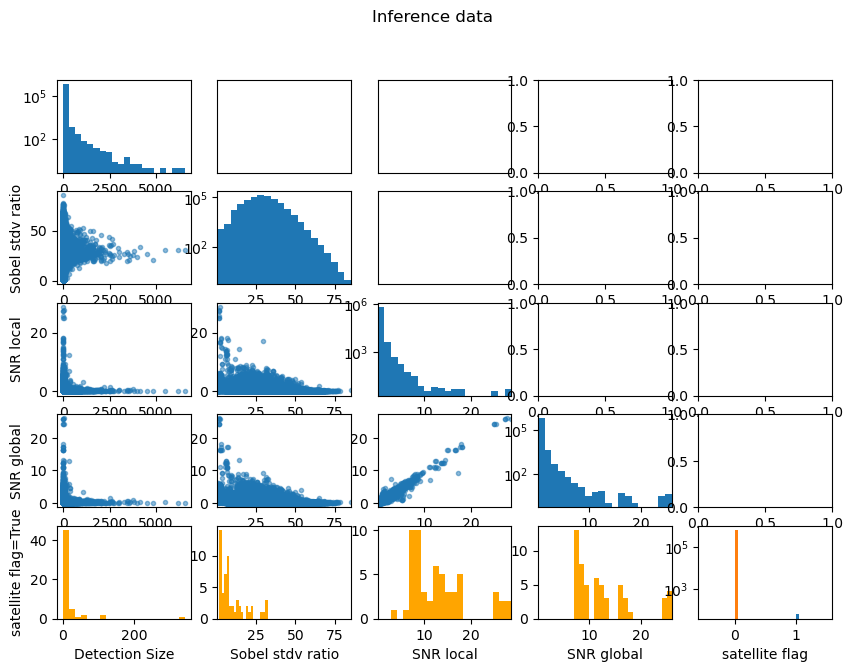

In [175]:
df = df_inf_nodups
size = 5
fig, ax = plt.subplots(size,size)

ax[0,0].hist(df["detection_size"], bins=20)
ax[1,0].plot(df["detection_size"], df["sobel_norm_stdv_rat"],'.', alpha=.5)
ax[2,0].plot(df["detection_size"], df["snr_local_new"],'.', alpha=.5)


# ax[0,0].hist(df["detection_size"])
ax[1,1].hist(df["sobel_norm_stdv_rat"], bins=20)
ax[2,1].plot(df["sobel_norm_stdv_rat"], df["snr_local_new"],'.', alpha=.5)

ax[2,2].hist(df["snr_local_new"], bins=20)

fig.suptitle("Inference data")
ax[size-1,0].set_xlabel("Detection Size")
ax[1,0].set_ylabel("Sobel stdv ratio")
ax[2,0].set_ylabel("SNR local")
ax[size-1,1].set_xlabel("Sobel stdv ratio")
ax[size-1,2].set_xlabel("SNR local")

ax[0,0].set_yscale("log")
ax[1,1].set_yscale("log")
ax[2,2].set_yscale("log")

ax[0,1].set_xticks([])
ax[0,2].set_xticks([])
ax[1,2].set_xticks([])
ax[0,1].set_yticks([])
ax[0,2].set_yticks([])
ax[1,2].set_yticks([])

ax[3,2].plot(df["snr_local_new"], df["snr_global_new"],'.', alpha=.5)
ax[3,0].plot(df["detection_size"], df["snr_global_new"],'.', alpha=.5)
ax[3,1].plot(df["sobel_norm_stdv_rat"], df["snr_global_new"],'.', alpha=.5)
ax[3,3].hist(df["snr_global_new"], bins=20)
ax[size-1,3].set_xlabel("SNR global")
ax[3,0].set_ylabel("SNR global")
ax[3,3].set_yscale("log")

ax[size-1,4].set_xlabel("satellite flag")
ax[4,0].set_ylabel("satellite flag=True")


ax[4,4].hist(df[df["satellite_flag"]==1]["satellite_flag"], bins=20,label="True")
ax[4,4].hist(df[df["satellite_flag"]==0]["satellite_flag"], bins=20,label="False")
ax[4,4].set_yscale("log")


ax[4,3].hist(df[df["satellite_flag"]==1]["snr_global_new"], bins=20,label="True", color='orange')
# ax[4,3].hist(df[df["satellite_flag"]==0]["snr_global_new"], bins=20,label="False")
ax[4,2].hist(df[df["satellite_flag"]==1]["snr_local_new"], bins=20,label="True", color='orange')
ax[4,1].hist(df[df["satellite_flag"]==1]["sobel_norm_stdv_rat"], bins=20,label="True", color='orange')
ax[4,0].hist(df[df["satellite_flag"]==1]["detection_size"], bins=20,label="True", color='orange')

detection_size_range = (df["detection_size"].min(), df["detection_size"].max())
sobel_range = (df["sobel_norm_stdv_rat"].min(), df["sobel_norm_stdv_rat"].max())
snr_local_range = (df["snr_local_new"].min(), df["snr_local_new"].max())
snr_global_range = (df["snr_global_new"].min(), df["snr_global_new"].max())

for i in range(size):
    # ax[i,0].set_xlim(detection_size_range)
    if i >= 1:
        ax[i,1].set_xlim(sobel_range)
    if i >= 2:
        ax[i,2].set_xlim(snr_local_range)
    if i >= 3:
        ax[i,3].set_xlim(snr_global_range)

plt.show()


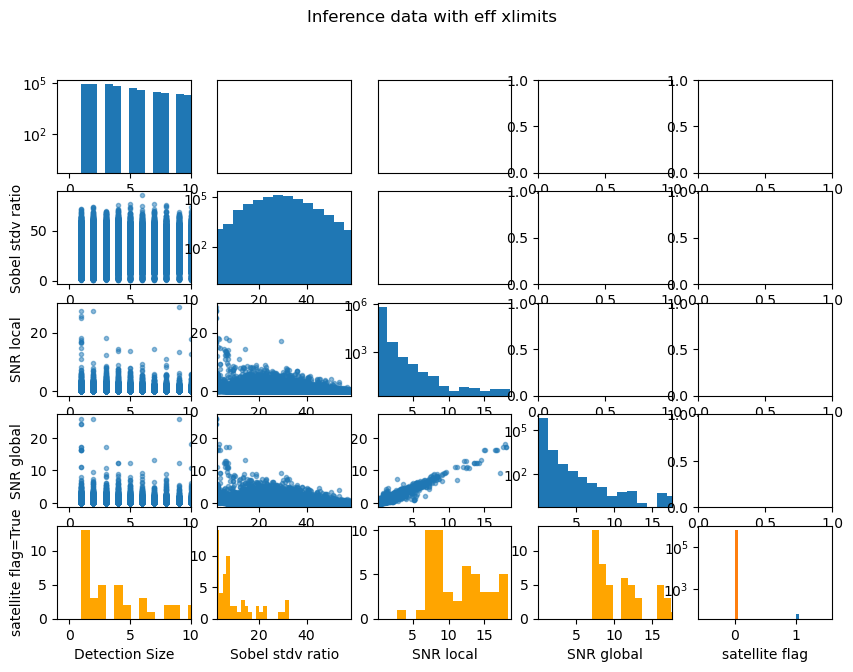

In [18]:
df = df_inf_nodups


size = 5
fig, ax = plt.subplots(size,size)

fig.suptitle("Inference data with eff xlimits")

ax[0,0].hist(df["detection_size"], bins=10000)
ax[1,0].plot(df["detection_size"], df["sobel_norm_stdv_rat"],'.', alpha=.5)
ax[2,0].plot(df["detection_size"], df["snr_local_new"],'.', alpha=.5)


# ax[0,0].hist(df["detection_size"])
ax[1,1].hist(df["sobel_norm_stdv_rat"], bins=20)
ax[2,1].plot(df["sobel_norm_stdv_rat"], df["snr_local_new"],'.', alpha=.5)

ax[2,2].hist(df["snr_local_new"], bins=20)


ax[size-1,0].set_xlabel("Detection Size")
ax[1,0].set_ylabel("Sobel stdv ratio")
ax[2,0].set_ylabel("SNR local")
ax[size-1,1].set_xlabel("Sobel stdv ratio")
ax[size-1,2].set_xlabel("SNR local")

ax[0,0].set_yscale("log")
ax[1,1].set_yscale("log")
ax[2,2].set_yscale("log")

ax[0,1].set_xticks([])
ax[0,2].set_xticks([])
ax[1,2].set_xticks([])
ax[0,1].set_yticks([])
ax[0,2].set_yticks([])
ax[1,2].set_yticks([])

ax[3,2].plot(df["snr_local_new"], df["snr_global_new"],'.', alpha=.5)
ax[3,0].plot(df["detection_size"], df["snr_global_new"],'.', alpha=.5)
ax[3,1].plot(df["sobel_norm_stdv_rat"], df["snr_global_new"],'.', alpha=.5)
ax[3,3].hist(df["snr_global_new"], bins=20)
ax[size-1,3].set_xlabel("SNR global")
ax[3,0].set_ylabel("SNR global")
ax[3,3].set_yscale("log")

ax[size-1,4].set_xlabel("satellite flag")
ax[4,0].set_ylabel("satellite flag=True")


ax[4,4].hist(df[df["satellite_flag"]==1]["satellite_flag"], bins=20,label="True")
ax[4,4].hist(df[df["satellite_flag"]==0]["satellite_flag"], bins=20,label="False")
ax[4,4].set_yscale("log")


ax[4,3].hist(df[df["satellite_flag"]==1]["snr_global_new"], bins=20,label="True", color='orange')
# ax[4,3].hist(df[df["satellite_flag"]==0]["snr_global_new"], bins=20,label="False")
ax[4,2].hist(df[df["satellite_flag"]==1]["snr_local_new"], bins=20,label="True", color='orange')
ax[4,1].hist(df[df["satellite_flag"]==1]["sobel_norm_stdv_rat"], bins=20,label="True", color='orange')
ax[4,0].hist(df[df["satellite_flag"]==1]["detection_size"], bins=500,label="True", color='orange')




# detection_size_range = (df_eff_nodups["detection_size"].min(), df_eff_nodups["detection_size"].max())
detection_size_range = (-1, 10)

sobel_range = (df_eff_nodups["sobel_norm_stdv_rat"].min(), df_eff_nodups["sobel_norm_stdv_rat"].max())
snr_local_range = (df_eff_nodups["snr_local"].min(), df_eff_nodups["snr_local"].max())
snr_global_range = (df_eff_nodups["snr_global"].min(), df_eff_nodups["snr_global"].max())

for i in range(size):
    ax[i,0].set_xlim(detection_size_range)
    if i >= 1:
        ax[i,1].set_xlim(sobel_range)
    if i >= 2:
        ax[i,2].set_xlim(snr_local_range)
    if i >= 3:
        ax[i,3].set_xlim(snr_global_range)

        
plt.show()

In [34]:
df_inf_nodups_again = pd.read_csv(base_path+"df_inf_wdups")

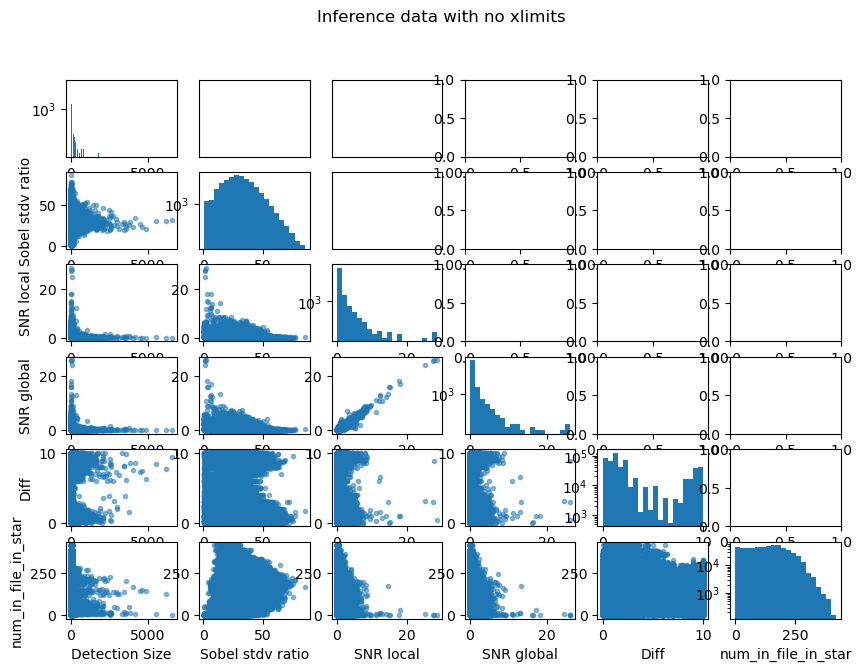

In [36]:
df = df_inf_nodups_again[df_inf_nodups_again['is_smaller_dup']==0]


size = 6
fig, ax = plt.subplots(size,size)

fig.suptitle("Inference data with no xlimits")

ax[0,0].hist(df["detection_size"], bins=10000)
ax[1,0].plot(df["detection_size"], df["sobel_norm_stdv_rat"],'.', alpha=.5)
ax[2,0].plot(df["detection_size"], df["snr_local_new"],'.', alpha=.5)


# ax[0,0].hist(df["detection_size"])
ax[1,1].hist(df["sobel_norm_stdv_rat"], bins=20)
ax[2,1].plot(df["sobel_norm_stdv_rat"], df["snr_local_new"],'.', alpha=.5)

ax[2,2].hist(df["snr_local_new"], bins=20)


ax[size-1,0].set_xlabel("Detection Size")
ax[1,0].set_ylabel("Sobel stdv ratio")
ax[2,0].set_ylabel("SNR local")
ax[size-1,1].set_xlabel("Sobel stdv ratio")
ax[size-1,2].set_xlabel("SNR local")

ax[0,0].set_yscale("log")
ax[1,1].set_yscale("log")
ax[2,2].set_yscale("log")

ax[0,1].set_xticks([])
ax[0,2].set_xticks([])
ax[1,2].set_xticks([])
ax[0,1].set_yticks([])
ax[0,2].set_yticks([])
ax[1,2].set_yticks([])

ax[3,2].plot(df["snr_local_new"], df["snr_global_new"],'.', alpha=.5)
ax[3,0].plot(df["detection_size"], df["snr_global_new"],'.', alpha=.5)
ax[3,1].plot(df["sobel_norm_stdv_rat"], df["snr_global_new"],'.', alpha=.5)
ax[3,3].hist(df["snr_global_new"], bins=20)
ax[size-1,3].set_xlabel("SNR global")
ax[3,0].set_ylabel("SNR global")
ax[3,3].set_yscale("log")

# ax[size-1,5].set_xlabel("satellite flag")
# ax[5,0].set_ylabel("satellite flag=True")
# ax[5,4].hist(df[df["satellite_flag"]==1]["satellite_flag"], bins=20,label="True")
# ax[5,4].hist(df[df["satellite_flag"]==0]["satellite_flag"], bins=20,label="False")
# ax[5,4].set_yscale("log")
# ax[5,3].hist(df[df["satellite_flag"]==1]["snr_global_new"], bins=20,label="True", color='orange')
# # a5[4,3].hist(df[df["satellite_flag"]==0]["snr_global_new"], bins=20,label="False")
# ax[5,2].hist(df[df["satellite_flag"]==1]["snr_local_new"], bins=20,label="True", color='orange')
# ax[5,1].hist(df[df["satellite_flag"]==1]["sobel_norm_stdv_rat"], bins=20,label="True", color='orange')
# ax[5,0].hist(df[df["satellite_flag"]==1]["detection_size"], bins=500,label="True", color='orange')

ax[4,2].plot(df["snr_local_new"], df["Diff"],'.', alpha=.5)
ax[4,0].plot(df["detection_size"], df["Diff"],'.', alpha=.5)
ax[4,1].plot(df["sobel_norm_stdv_rat"], df["Diff"],'.', alpha=.5)
ax[4,4].hist(df["Diff"], bins=20)
ax[4,3].plot(df["snr_global_new"], df["Diff"],'.', alpha=.5)

ax[size-1,4].set_xlabel("Diff")
ax[4,0].set_ylabel("Diff")
ax[4,4].set_yscale("log")

thenext=5
ax[thenext,2].plot(df["snr_local_new"], df["num_in_file_in_star"],'.', alpha=.5)
ax[thenext,0].plot(df["detection_size"], df["num_in_file_in_star"],'.', alpha=.5)
ax[thenext,1].plot(df["sobel_norm_stdv_rat"], df["num_in_file_in_star"],'.', alpha=.5)
ax[thenext,thenext].hist(df["num_in_file_in_star"], bins=20)
ax[thenext,3].plot(df["snr_global_new"], df["num_in_file_in_star"],'.', alpha=.5)
ax[thenext,4].plot(df["Diff"], df["num_in_file_in_star"],'.', alpha=.5)

ax[size-1,thenext].set_xlabel("num_in_file_in_star")
ax[thenext,0].set_ylabel("num_in_file_in_star")
ax[thenext,thenext].set_yscale("log")

# detection_size_range = (df_eff_nodups["detection_size"].min(), df_eff_nodups["detection_size"].max())
# detection_size_range = (-1, 10)

# sobel_range = (df_eff_nodups["sobel_norm_stdv_rat"].min(), df_eff_nodups["sobel_norm_stdv_rat"].max())
# snr_local_range = (df_eff_nodups["snr_local"].min(), df_eff_nodups["snr_local"].max())
# snr_global_range = (df_eff_nodups["snr_global"].min(), df_eff_nodups["snr_global"].max())

# for i in range(size):
#     ax[i,0].set_xlim(detection_size_range)
#     if i >= 1:
#         ax[i,1].set_xlim(sobel_range)
#     if i >= 2:
#         ax[i,2].set_xlim(snr_local_range)
#     if i >= 3:
#         ax[i,3].set_xlim(snr_global_range)

        
plt.show()

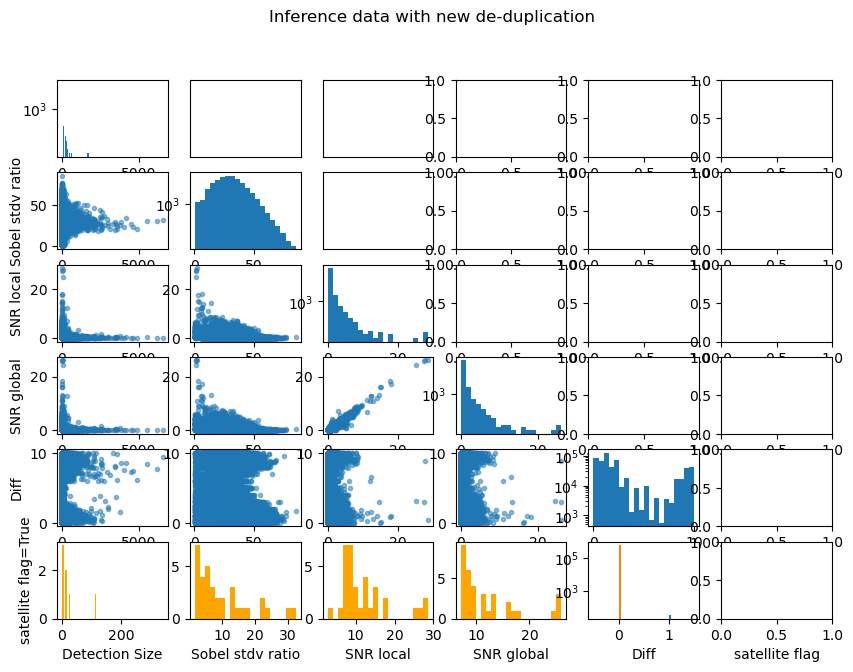

In [10]:
df = df_inf_nodups


size = 6
fig, ax = plt.subplots(size,size)

fig.suptitle("Inference data with new de-duplication")

ax[0,0].hist(df["detection_size"], bins=10000)
ax[1,0].plot(df["detection_size"], df["sobel_norm_stdv_rat"],'.', alpha=.5)
ax[2,0].plot(df["detection_size"], df["snr_local_new"],'.', alpha=.5)


# ax[0,0].hist(df["detection_size"])
ax[1,1].hist(df["sobel_norm_stdv_rat"], bins=20)
ax[2,1].plot(df["sobel_norm_stdv_rat"], df["snr_local_new"],'.', alpha=.5)

ax[2,2].hist(df["snr_local_new"], bins=20)


ax[size-1,0].set_xlabel("Detection Size")
ax[1,0].set_ylabel("Sobel stdv ratio")
ax[2,0].set_ylabel("SNR local")
ax[size-1,1].set_xlabel("Sobel stdv ratio")
ax[size-1,2].set_xlabel("SNR local")

ax[0,0].set_yscale("log")
ax[1,1].set_yscale("log")
ax[2,2].set_yscale("log")

ax[0,1].set_xticks([])
ax[0,2].set_xticks([])
ax[1,2].set_xticks([])
ax[0,1].set_yticks([])
ax[0,2].set_yticks([])
ax[1,2].set_yticks([])

ax[3,2].plot(df["snr_local_new"], df["snr_global_new"],'.', alpha=.5)
ax[3,0].plot(df["detection_size"], df["snr_global_new"],'.', alpha=.5)
ax[3,1].plot(df["sobel_norm_stdv_rat"], df["snr_global_new"],'.', alpha=.5)
ax[3,3].hist(df["snr_global_new"], bins=20)
ax[size-1,3].set_xlabel("SNR global")
ax[3,0].set_ylabel("SNR global")
ax[3,3].set_yscale("log")

ax[size-1,5].set_xlabel("satellite flag")
ax[5,0].set_ylabel("satellite flag=True")
ax[5,4].hist(df[df["satellite_flag"]==1]["satellite_flag"], bins=20,label="True")
ax[5,4].hist(df[df["satellite_flag"]==0]["satellite_flag"], bins=20,label="False")
ax[5,4].set_yscale("log")
ax[5,3].hist(df[df["satellite_flag"]==1]["snr_global_new"], bins=20,label="True", color='orange')
# a5[4,3].hist(df[df["satellite_flag"]==0]["snr_global_new"], bins=20,label="False")
ax[5,2].hist(df[df["satellite_flag"]==1]["snr_local_new"], bins=20,label="True", color='orange')
ax[5,1].hist(df[df["satellite_flag"]==1]["sobel_norm_stdv_rat"], bins=20,label="True", color='orange')
ax[5,0].hist(df[df["satellite_flag"]==1]["detection_size"], bins=500,label="True", color='orange')

ax[4,2].plot(df["snr_local_new"], df["Diff"],'.', alpha=.5)
ax[4,0].plot(df["detection_size"], df["Diff"],'.', alpha=.5)
ax[4,1].plot(df["sobel_norm_stdv_rat"], df["Diff"],'.', alpha=.5)
ax[4,4].hist(df["Diff"], bins=20)
ax[4,3].plot(df["snr_global_new"], df["Diff"],'.', alpha=.5)

ax[size-1,4].set_xlabel("Diff")
ax[4,0].set_ylabel("Diff")
ax[4,4].set_yscale("log")



# detection_size_range = (df_eff_nodups["detection_size"].min(), df_eff_nodups["detection_size"].max())
# detection_size_range = (-1, 10)

# sobel_range = (df_eff_nodups["sobel_norm_stdv_rat"].min(), df_eff_nodups["sobel_norm_stdv_rat"].max())
# snr_local_range = (df_eff_nodups["snr_local"].min(), df_eff_nodups["snr_local"].max())
# snr_global_range = (df_eff_nodups["snr_global"].min(), df_eff_nodups["snr_global"].max())

# for i in range(size):
#     ax[i,0].set_xlim(detection_size_range)
#     if i >= 1:
#         ax[i,1].set_xlim(sobel_range)
#     if i >= 2:
#         ax[i,2].set_xlim(snr_local_range)
#     if i >= 3:
#         ax[i,3].set_xlim(snr_global_range)

        
plt.show()

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,num_consecutive_up,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup
0,0,0,0,0,0,0,0,0,0,0,...,267.0,52.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,267.0,0.0,0.0,0.0,[1],0.0
1,1,1,1,1,1,1,1,1,1,1,...,266.0,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[0 2],1.0
2,2,2,2,2,2,2,2,2,2,2,...,266.0,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[1 3],0.0
3,3,3,3,3,3,3,3,3,3,3,...,265.0,54.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,265.0,0.0,0.0,0.0,[2 5 6],1.0
4,4,4,4,4,4,4,4,4,4,4,...,154.0,248.0,[ 0 1 2 3 73 81 111 140 219 254 256 2...,[ 5 6 7 8 9 10 11 13 14 15 17 ...,248.0,0.0,0.0,0.0,[],0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894770,894770,894770,894770,894770,894770,894770,894770,894770,894770,290,...,126.0,148.0,[894481 894482 894484 894485 894487 894488 894...,[894480 894483 894486 894492 894494 894498 894...,148.0,0.0,0.0,0.0,[894768 894769 894771],1.0
894771,894771,894771,894771,894771,894771,894771,894771,894771,894771,291,...,197.0,97.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894620 894627 894632 894...,197.0,0.0,0.0,0.0,[894769 894770 894772],0.0
894772,894772,894772,894772,894772,894772,894772,894772,894772,894772,292,...,201.0,52.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894635 894636 894...,201.0,0.0,0.0,0.0,[894771],1.0
894773,894773,894773,894773,894773,894773,894773,894773,894773,894773,293,...,203.0,49.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894639 894640 894...,203.0,0.0,0.0,0.0,[894774],0.0


In [140]:
#i put it in rff
# def add_satellite_flag(df, new=True):
#     df['satellite_flag_2_2_new'] = np.zeros(len(df))
#     df['satellite_flag_1_7_new'] = np.zeros(len(df))
#     df['satellite_flag'] = np.zeros(len(df))
#     if new==True:
#         for i, row in df.iterrows():            
#             if row['max_num_consecutive']>2 and row['snr_global_new']>2:
#                 df.at[i, 'satellite_flag_2_2_new']=1
#             if row['max_num_consecutive']>1 and row['snr_global_new']>7:
#                 df.at[i, 'satellite_flag_1_7_new']=1
#             if df.at[i, 'satellite_flag_2_2_new']==1 and df.at[i, 'satellite_flag_1_7_new']==1:
#                 df.at[i, 'satellite_flag']=1
#     else:
#         for i, row in df.iterrows():            
#             if row['max_num_consecutive']>2 and row['snr_global']>2:
#                 df.at[i, 'satellite_flag_2_2_new']=1
#             if row['max_num_consecutive']>1 and row['snr_global']>7:
#                 df.at[i, 'satellite_flag_1_7_new']=1
#             if df.at[i, 'satellite_flag_2_2_new']==1 and df.at[i, 'satellite_flag_1_7_new']==1:
#                 df.at[i, 'satellite_flag']=1
#     return df


# #looking for multiple transients that progress
# #something like - num-consecutive

# def add_num_consecutive(df):
#     df["num_in_file"] = np.zeros(len(df))
#     df["num_consecutive_up"] = np.zeros(len(df))
#     df["num_consecutive_down"] = np.zeros(len(df))
#     df["possible_up_indices"] = np.zeros(len(df), dtype=object)
#     df["possible_down_indices"] = np.zeros(len(df), dtype=object)
#     df["max_num_consecutive"] = np.zeros(len(df))
#     for fname in np.unique(df["filename"]):
#         for quad in np.unique(df[df["filename"]==fname]["quadrant"]):
#             subsection = df[(df["filename"]==fname) * (df["quadrant"]==quad)]
#             num_in_file_here = len(subsection)
#             for index in subsection.index:
#                 df.at[index, "num_in_file"]=num_in_file_here
#                 # print(index)
#                 # print(num_in_file_here)
#                 # print(df.loc[index]["num_in_file"])
#                 if num_in_file_here<3:
#                     continue #leaves num_consecutive at zero
#                 original_col = subsection.loc[index]["col_from_nn"] #x
#                 original_row = subsection.loc[index]["row_from_nn"] #y
#                 num_going_up = 0
#                 num_going_down = 0
#                 possible_up_indices = []
#                 possible_down_indices = []
#                 for i, rrow in subsection.iterrows():
#                     # print(rrow["col_from_nn"])
#                     # print(original_col)
#                     if (rrow["col_from_nn"] > original_col) * (rrow["row_from_nn"] > original_row): #if both true
#                         num_going_up+=1
#                         possible_up_indices.append(i)
#                     elif (rrow["col_from_nn"] < original_col) * (rrow["row_from_nn"] < original_row):
#                         num_going_up+=1
#                         possible_up_indices.append(i)
#                     elif (rrow["col_from_nn"] < original_col) * (rrow["row_from_nn"] > original_row):
#                         num_going_down+=1
#                         possible_down_indices.append(i)
#                     elif (rrow["col_from_nn"] > original_col) * (rrow["row_from_nn"] < original_row):
#                         num_going_down+=1
#                         possible_down_indices.append(i)
#                 df.at[index, "max_num_consecutive"] = np.max([num_going_up, num_going_down])
#                 # print(possible_down_indices)
#                 df.at[index, "num_consecutive_up"] = num_going_up
#                 df.at[index, "num_consecutive_down"] = num_going_down
#                 df.at[index, "possible_down_indices"] = np.array(possible_down_indices)
#                 df.at[index, "possible_up_indices"] = np.array(possible_up_indices)
#     return df
                
                
        

In [150]:
df_inf_nodups['quadrant']=df_inf_nodups['quad']

/tmp/ipykernel_7973/801550404.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_inf_nodups['quadrant']=df_inf_nodups['quad']


In [151]:
df_inf_nodups = add_num_consecutive(df_inf_nodups)


/tmp/ipykernel_7973/3462340558.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["num_in_file"] = np.zeros(len(df))
/tmp/ipykernel_7973/3462340558.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["num_consecutive_up"] = np.zeros(len(df))
/tmp/ipykernel_7973/3462340558.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-doc

KeyboardInterrupt: 

In [142]:
# df_eff_nodups = add_num_consecutive(df_eff)

In [143]:
df_eff = add_satellite_flag(df_eff, new=False)

In [ ]:
df_inf_nodups = add_satellite_flag(df_inf_nodups, new=True)

In [162]:
df_inf_nodups

,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,...,quadrant,num_in_file,num_consecutive_up,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag
893683,893683,893683,893683,893683,893683,893683,893683,893683,76,ztf_20221020294271_000449_zr_c09_x_0005.,...,1,481.0,221.0,259.0,[893610 893611 893612 893613 893614 893615 893...,[893607 893608 893609 893620 893623 893625 893...,259.0,0.0,0.0,0.0
333081,333081,333081,333081,333081,333081,333081,333081,333081,190,ztf_20221020163819_000640_zg_c09_x_0019.,...,2,513.0,218.0,175.0,[332892 332896 332900 332908 332910 332914 332...,[332891 332894 332895 332897 332898 332899 332...,218.0,0.0,0.0,0.0
35773,35773,35773,35773,35773,35773,35773,35773,35773,33,ztf_20221020163819_000640_zg_c11_x_0025.,...,1,453.0,105.0,299.0,[35755 35759 35766 35770 35775 35776 35784 357...,[35741 35743 35745 35747 35750 35752 35753 357...,299.0,0.0,0.0,0.0
457544,457544,457544,457544,457544,457544,457544,457544,457544,114,ztf_20221020163819_000640_zg_c11_x_0024.,...,1,500.0,163.0,195.0,[457430 457432 457433 457434 457436 457437 457...,[457435 457438 457441 457445 457448 457450 457...,195.0,0.0,0.0,0.0
737765,737765,737765,737765,737765,737765,737765,737765,737765,83,ztf_20221020163819_000640_zg_c04_x_0006.,...,3,427.0,195.0,230.0,[737683 737684 737686 737688 737692 737697 737...,[737682 737685 737687 737689 737690 737691 737...,230.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
632823,632823,632823,632823,632823,632823,632823,632823,632823,4,ztf_20221020154120_000640_zi_c15_x_0028.,...,3,122.0,10.0,111.0,[632819 632820 632824 632860 632861 632862 632...,[632821 632822 632825 632826 632827 632828 632...,111.0,1.0,1.0,1.0
632831,632831,632831,632831,632831,632831,632831,632831,632831,12,ztf_20221020154120_000640_zi_c15_x_0028.,...,3,122.0,20.0,101.0,[632819 632820 632825 632826 632828 632829 632...,[632821 632822 632823 632824 632827 632830 632...,101.0,1.0,1.0,1.0
632830,632830,632830,632830,632830,632830,632830,632830,632830,11,ztf_20221020154120_000640_zi_c15_x_0028.,...,3,122.0,20.0,101.0,[632819 632820 632825 632826 632828 632829 632...,[632821 632822 632823 632824 632827 632831 632...,101.0,1.0,1.0,1.0
632829,632829,632829,632829,632829,632829,632829,632829,632829,10,ztf_20221020154120_000640_zi_c15_x_0028.,...,3,122.0,21.0,100.0,[632819 632820 632825 632826 632827 632828 632...,[632821 632822 632823 632824 632832 632833 632...,100.0,1.0,1.0,1.0


In [183]:
df_inf_nodups.iloc[0]


Unnamed: 0.8                                                            893683
Unnamed: 0.7                                                            893683
Unnamed: 0.6                                                            893683
Unnamed: 0.5                                                            893683
Unnamed: 0.4                                                            893683
Unnamed: 0.3                                                            893683
Unnamed: 0.2                                                            893683
Unnamed: 0.1                                                            893683
Unnamed: 0                                                                  76
filename                              ztf_20221020294271_000449_zr_c09_x_0005.
quad                                                                         1
type                                                                       pos
row_from_nn                                         

In [187]:
df_inf_nodups.sort_values('Diff')[:30]['Diff']

116151    0.0
757581    0.0
697516    0.0
517759    0.0
427457    0.0
689728    0.0
482001    0.0
170862    0.0
692819    0.0
351210    0.0
173419    0.0
567652    0.0
144146    0.0
604120    0.0
273019    0.0
819126    0.0
610613    0.0
292348    0.0
607480    0.0
240653    0.0
64112     0.0
352649    0.0
759562    0.0
441666    0.0
720941    0.0
370276    0.0
815587    0.0
558498    0.0
220300    0.0
676371    0.0
Name: Diff, dtype: float64

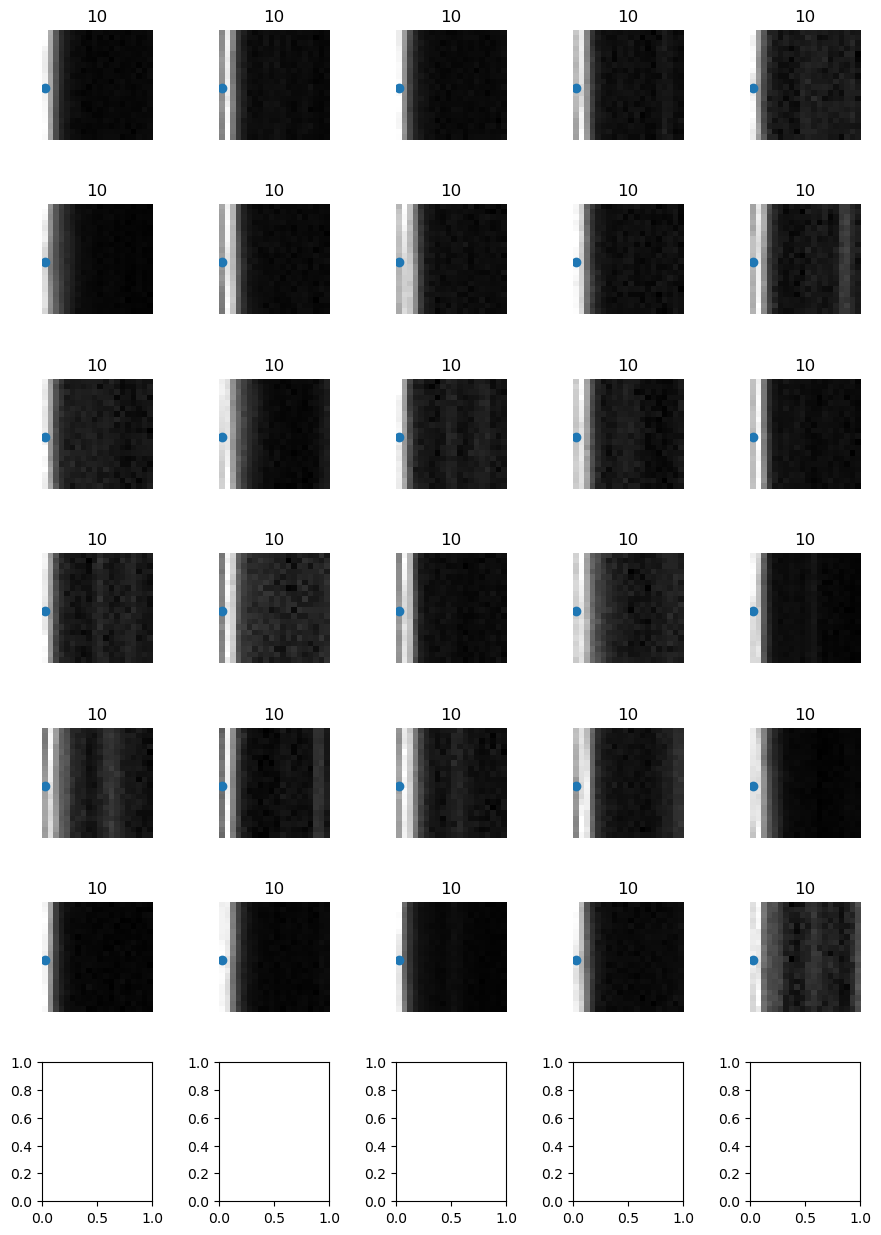

In [189]:
rff.inspect_df_with_quadrant(df_inf_nodups.sort_values('Diff')[-30:], '1020', imgsize=10, star=True, titlecol='Diff')

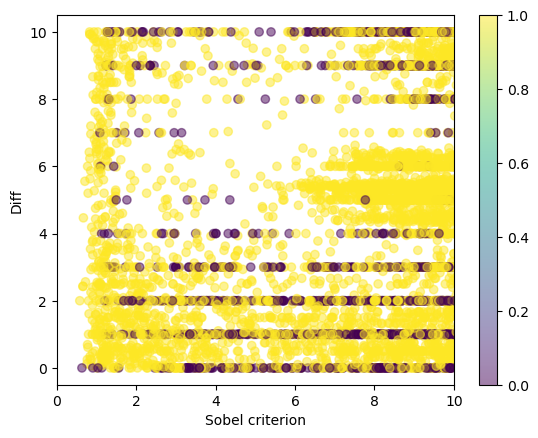

In [9]:
plt.scatter(df_inf_nodups["sobel_norm_stdv_rat"], df_inf_nodups["Diff"], alpha=.5, c=df_inf_nodups["detection_size"]>1)
plt.xlabel("Sobel criterion")
plt.ylabel("Diff")
plt.xlim(0,10)
plt.colorbar()

In [21]:
four = df_inf_nodups[df_inf_nodups["Diff"]==4]
              # 

In [43]:
fourish = df_inf_nodups[np.abs(df_inf_nodups["Diff"]-4)<.5]

In [44]:
fourish[np.abs(fourish["sobel_norm_stdv_rat"]-8)<.3]["Diff"]

151072    4.458333
375597    4.035714
560158    4.000000
383694    4.000000
238031    4.333333
720523    4.464286
720530    4.470588
151068    4.416667
353369    4.434783
640701    4.000000
678882    4.000000
182816    4.000000
353377    4.413793
720595    4.411765
720558    4.450000
720521    4.352941
182845    4.000000
320744    3.666667
484818    4.000000
Name: Diff, dtype: float64

In [25]:
fourish.loc[375597]

Unnamed: 0.8                                                            375597
Unnamed: 0.7                                                            375597
Unnamed: 0.6                                                            375597
Unnamed: 0.5                                                            375597
Unnamed: 0.4                                                            375597
Unnamed: 0.3                                                            375597
Unnamed: 0.2                                                            375597
Unnamed: 0.1                                                            375597
Unnamed: 0                                                                 175
filename                              ztf_20221020294271_000449_zr_c09_x_0001.
quad                                                                         1
type                                                                       pos
row_from_nn                                         

In [22]:
four[np.abs(four["sobel_norm_stdv_rat"]-8)<.3]

,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,...,quadrant,num_in_file,num_consecutive_up,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag
560158,560158,560158,560158,560158,560158,560158,560158,560158,255,ztf_20221020148032_000686_zg_c10_x_0028.,...,2,641.0,273.0,270.0,[559905 559906 559908 559910 559914 559917 559...,[559904 559907 559909 559911 559912 559913 559...,273.0,0.0,0.0,0.0
383694,383694,383694,383694,383694,383694,383694,383694,383694,277,ztf_20221020163819_000640_zg_c05_x_0014.,...,2,544.0,276.0,143.0,[383417 383418 383422 383424 383430 383435 383...,[383420 383423 383425 383428 383429 383434 383...,276.0,0.0,0.0,0.0
640701,640701,640701,640701,640701,640701,640701,640701,640701,54,ztf_20221020138241_000686_zi_c04_x_0008.,...,4,63.0,28.0,33.0,[640647 640648 640649 640650 640652 640656 640...,[640651 640653 640654 640655 640657 640658 640...,33.0,0.0,0.0,0.0
678882,678882,678882,678882,678882,678882,678882,678882,678882,400,ztf_20221020154120_000640_zi_c16_x_0000.,...,3,890.0,456.0,432.0,[678485 678486 678487 678490 678491 678492 678...,[678482 678483 678484 678488 678489 678495 678...,456.0,0.0,0.0,0.0
182816,182816,182816,182816,182816,182816,182816,182816,182816,510,ztf_20221020148032_000686_zg_c16_x_0010.,...,4,606.0,317.0,288.0,[182307 182310 182313 182315 182317 182318 182...,[182306 182308 182309 182311 182312 182314 182...,317.0,0.0,0.0,0.0
182845,182845,182845,182845,182845,182845,182845,182845,182845,539,ztf_20221020148032_000686_zg_c16_x_0010.,...,4,606.0,317.0,288.0,[182307 182310 182313 182315 182325 182327 182...,[182306 182308 182309 182311 182312 182314 182...,317.0,0.0,0.0,0.0
484818,484818,484818,484818,484818,484818,484818,484818,484818,40,ztf_20221020163819_000640_zg_c02_x_0018.,...,1,345.0,139.0,205.0,[484778 484779 484781 484782 484783 484784 484...,[484780 484820 484821 484822 484824 484825 484...,205.0,0.0,0.0,0.0


In [39]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

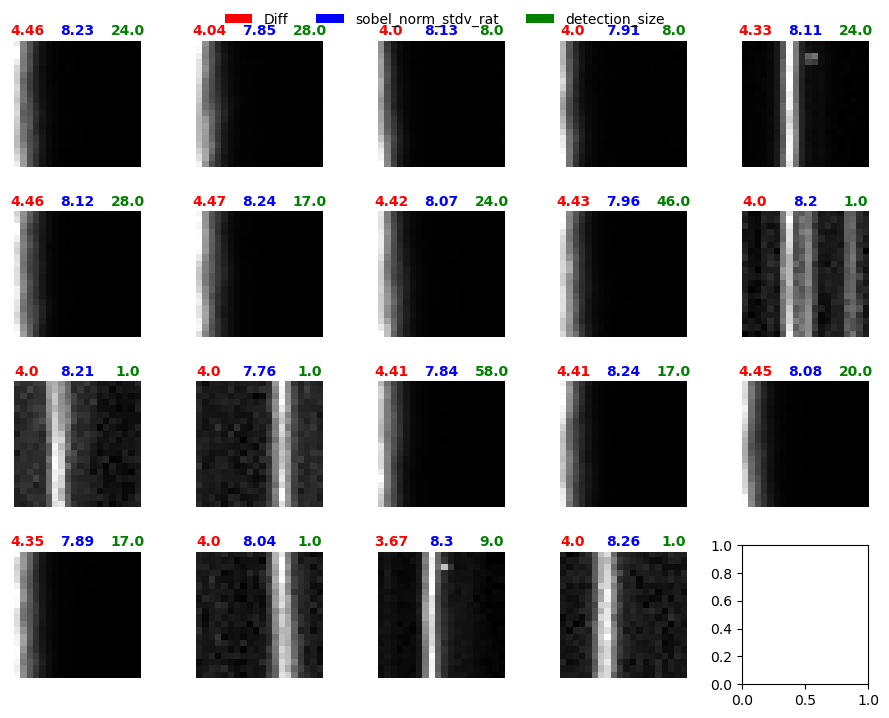

In [46]:
rff.inspect_df_w_stamp_color(fourish[np.abs(fourish["sobel_norm_stdv_rat"]-8)<.3], twodec=True, titlecol=["Diff","sobel_norm_stdv_rat", "detection_size"] )

In [47]:
df_eff_nodups[df_eff_nodups['detection_size']==1]

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,...,noise_global,local_average_outside,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y,sobel_norm_stdv_rat,sobel_norm_diffmax
7,211,211,211,219,654,ztf_20221020138241_000686_zi_c01_x_0023.,1,neg,2274.0,2607.0,...,113.314811,915.732619,118.070604,3.0,13.893259,18.988794,[[-6.29910278e+00 8.79998779e+00 -3.08250427e...,[[ 1.20938110e+00 1.13633423e+01 1.05956573e...,19.914131,18.988787
25,879,879,879,907,2764,ztf_20220820237546_000798_zr_c09_x_0003.,1,neg,1883.0,690.0,...,36.652718,905.313726,16.478754,3.0,5.364964,21.289196,[[-5.87097168e-01 -6.96701050e+00 1.99473419e...,[[ 2.33435669e+01 1.16744690e+01 8.67579651e...,29.515398,21.289198
27,778,778,778,802,2447,ztf_20221014162894_000802_zg_c01_x_0011.,1,neg,2696.0,159.0,...,42.824625,1402.704897,32.264341,3.0,6.766721,17.590389,[[-1.81101379e+01 -7.43601990e+00 -4.93087769e...,[[ 1.65580139e+01 2.06795197e+01 4.57061768e...,27.180988,17.590401
48,655,655,655,679,2051,ztf_20221020138241_000686_zi_c06_x_0015.,1,neg,1799.0,1737.0,...,30.839620,1133.490873,39.416475,3.0,7.435192,16.142019,[[ 1.59605408e+01 1.65798492e+01 1.04435730e...,[[-1.96603394e+00 -7.72262573e-01 7.30299377e...,22.547224,16.142027
83,1024,1024,1024,1056,3195,ztf_20220820237546_000798_zr_c08_x_0003.,1,neg,1767.0,767.0,...,33.303697,1117.901879,24.828589,4.0,7.795834,26.463770,[[-2.30823059e+01 -2.51890106e+01 1.07116699e...,[[ 1.35958557e+01 1.41314240e+01 1.91650391e...,27.487713,26.463789
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2449,2696,2696,2696,2771,4210,ztf_20220820237546_000798_zr_c09_x_0000.,1,pos,1517.0,2181.0,...,17.918651,371.017018,2006.280589,11.0,128.299058,5.992809,[[ 1.41132507e+01 5.67510742e+02 2.18093994e...,[[ 1.35885620e+00 1.80522308e+01 1.98925003e...,5.488069,5.992810
2480,2599,2599,2599,2671,3896,ztf_20220820237546_000798_zr_c16_x_0001.,1,pos,1718.0,601.0,...,26.993274,331.311429,2179.963473,16.0,161.519456,6.118369,[[-7.34124756e+00 3.88522797e+01 4.62889313e...,[[ 1.27493286e+01 1.04233856e+01 2.33592529e...,9.616514,6.118368
2593,2143,2143,2143,2209,2496,ztf_20220820237546_000798_zr_c08_x_0002.,1,pos,892.0,1262.0,...,18.866227,537.253069,3756.735212,9.0,156.716493,4.072553,[[ 2.94597473e+01 8.22070801e+02 3.61671680e...,[[-2.07034607e+01 5.19789581e+01 4.02413208e...,4.097493,4.072553
2795,2666,2666,2666,2740,4121,ztf_20221017148750_000831_zi_c04_x_0023.,1,pos,2493.0,89.0,...,11.605396,150.087746,1516.525902,17.0,138.287339,6.388612,[[ 4.34310455e+01 1.61777969e+02 3.47383148e...,[[ 1.61729279e+01 1.68930511e+01 5.82923279e...,7.082541,6.388612


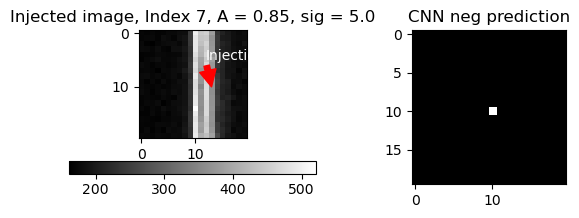

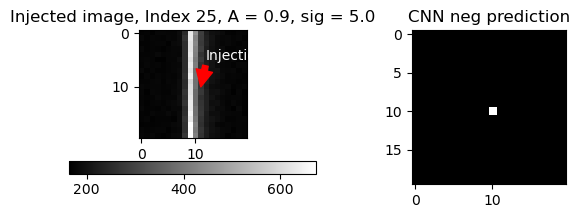

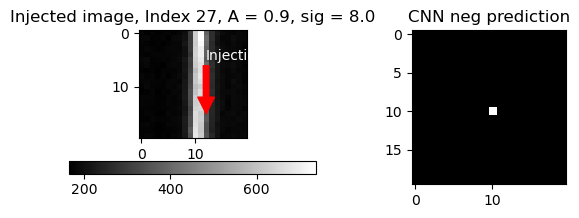

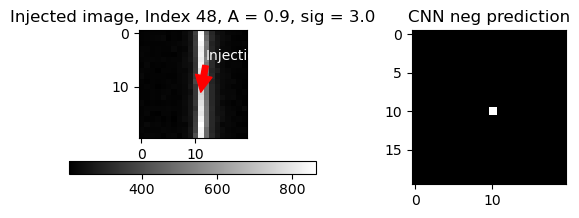

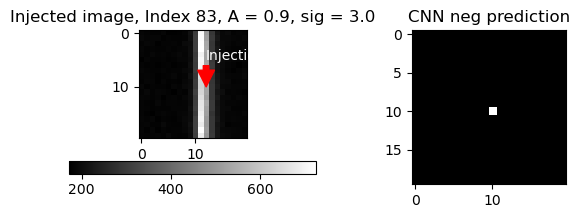

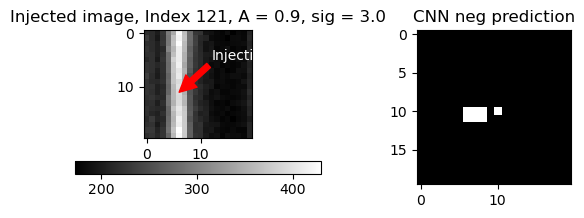

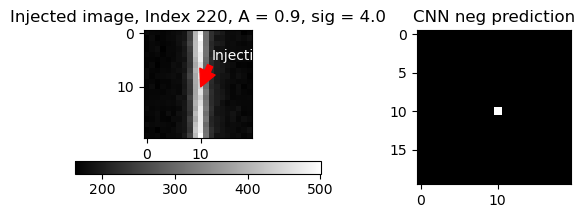

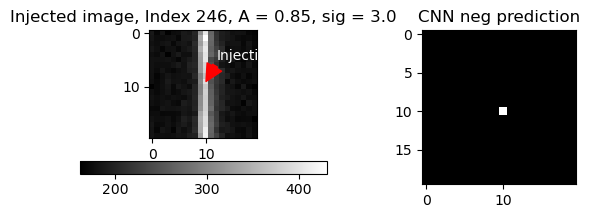

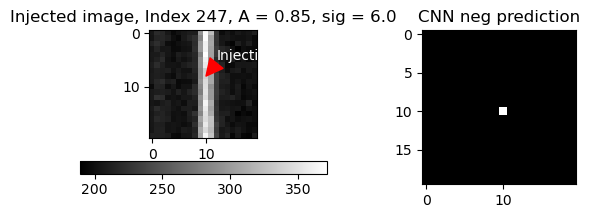

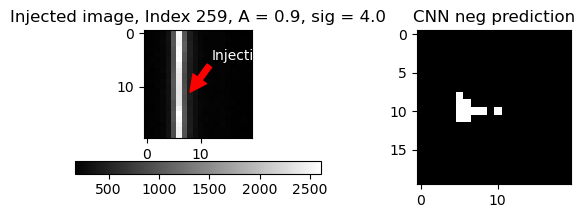

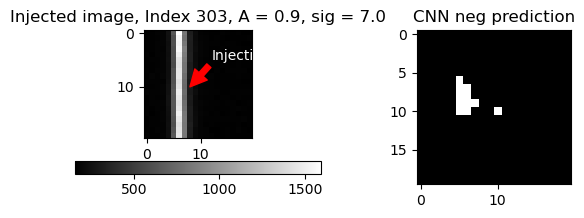

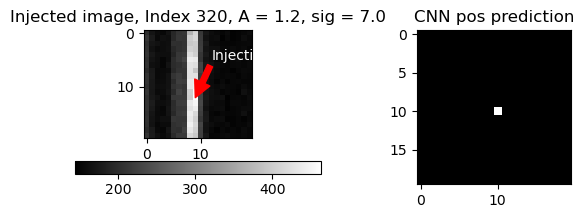

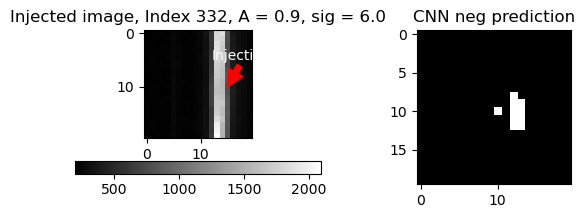

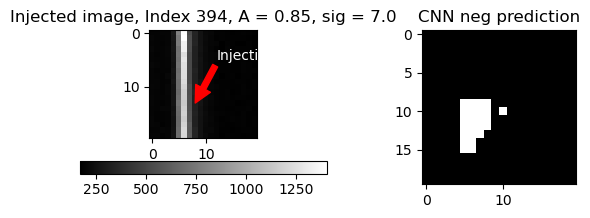

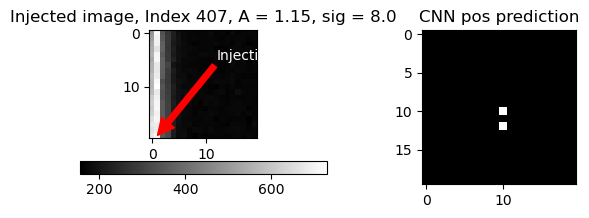

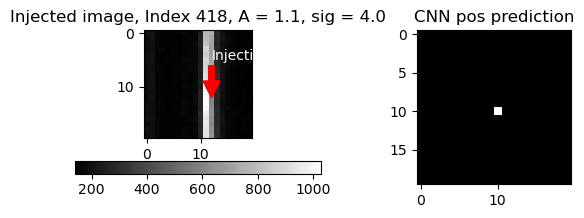

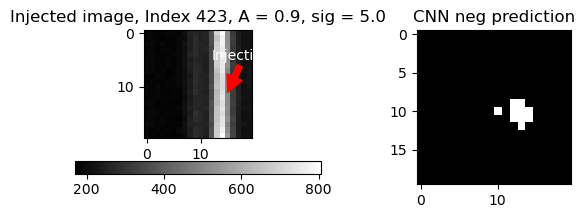

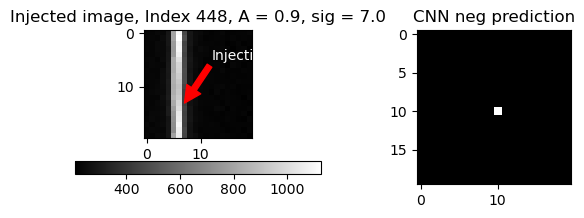

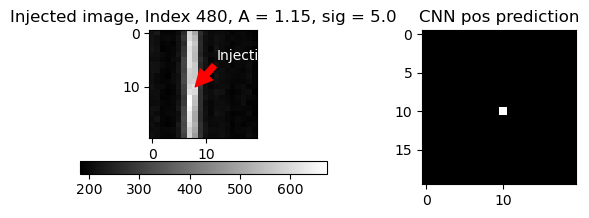

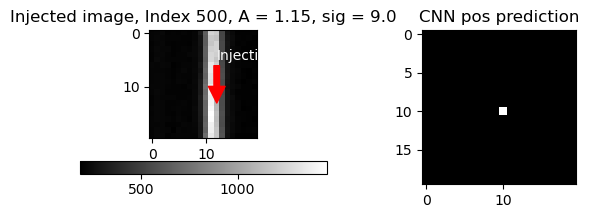

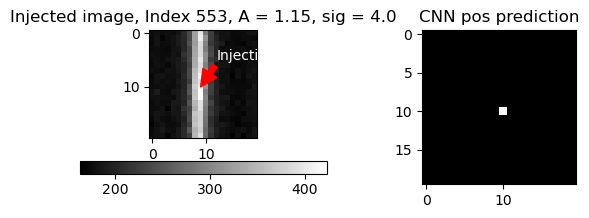

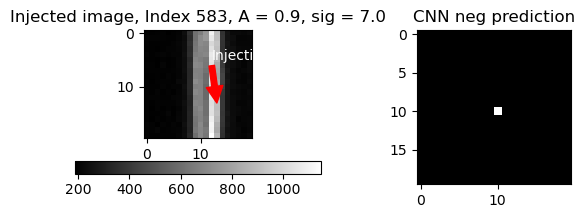

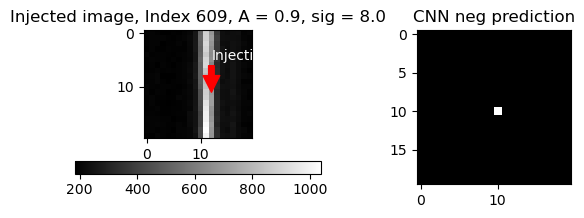

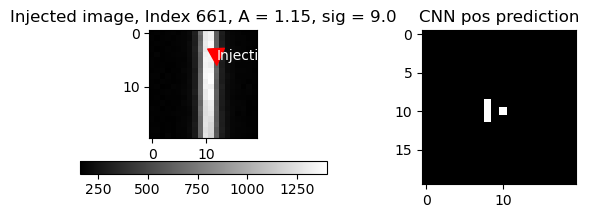

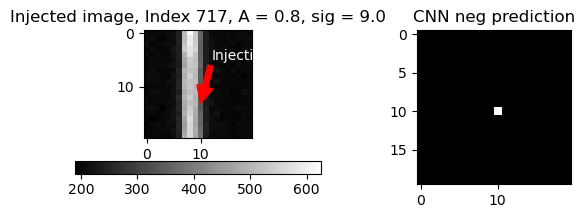

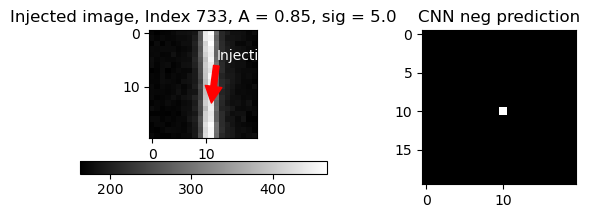

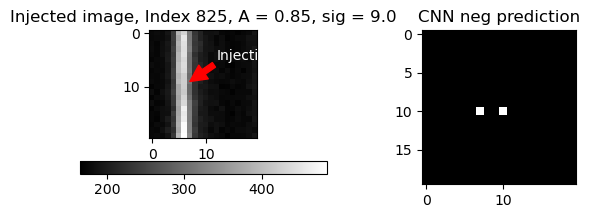

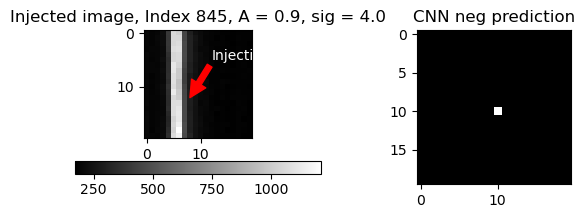

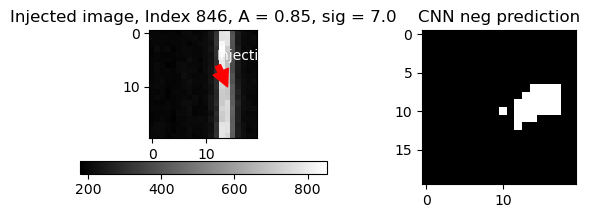

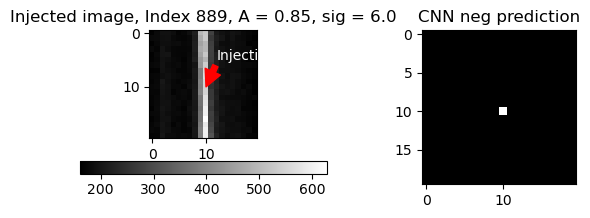

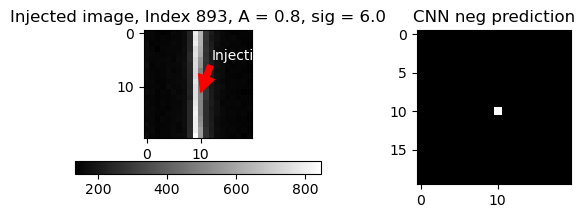

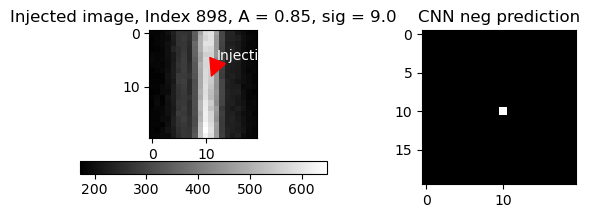

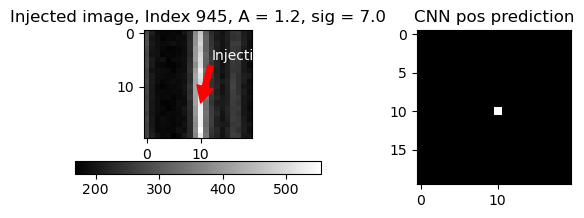

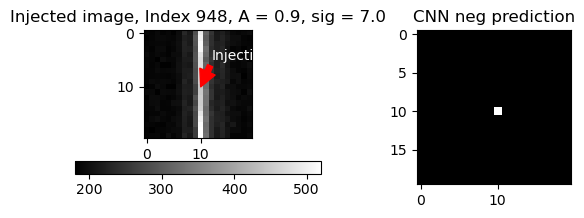

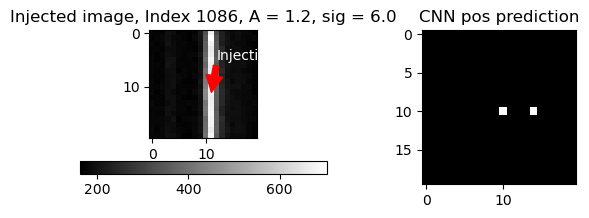

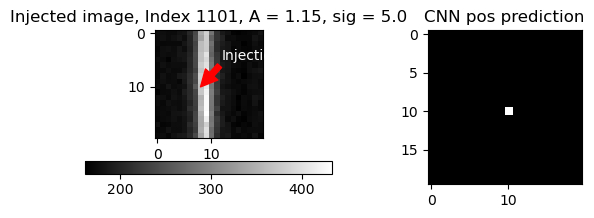

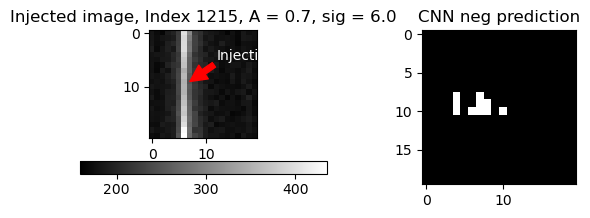

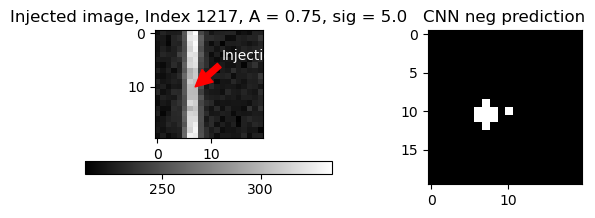

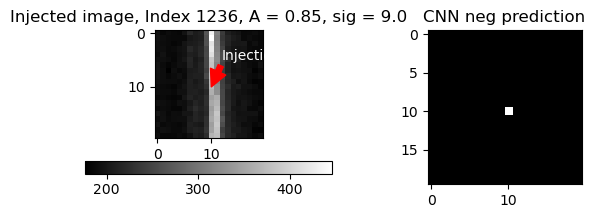

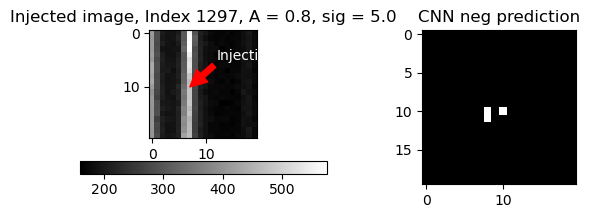

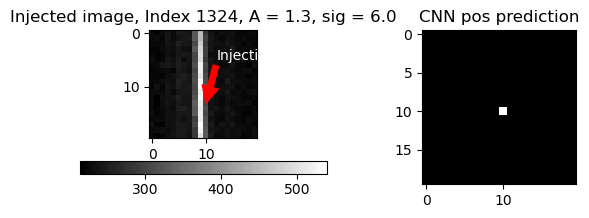

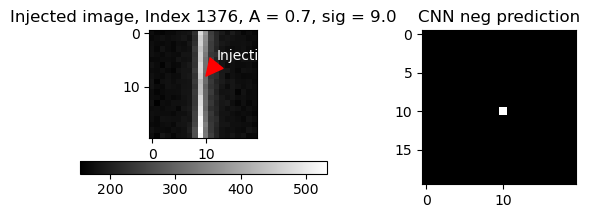

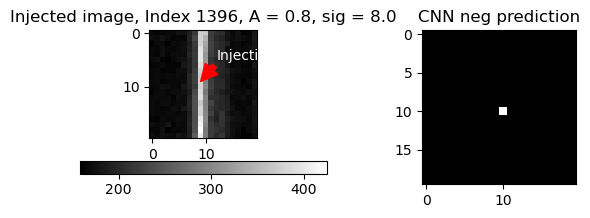

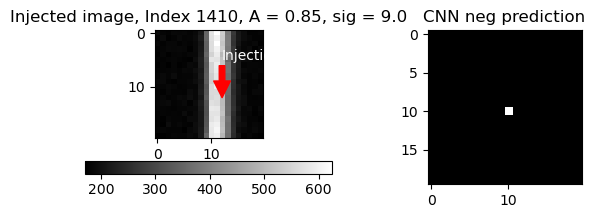

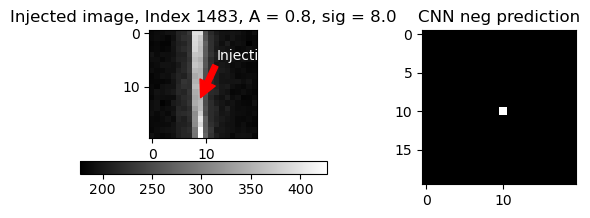

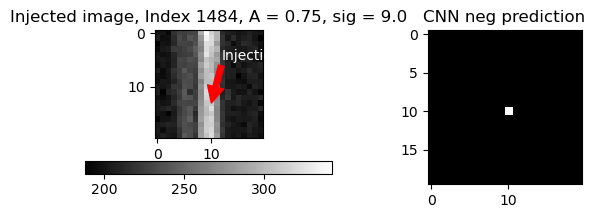

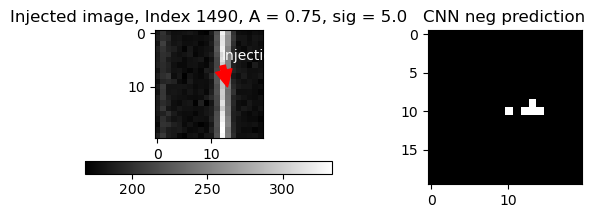

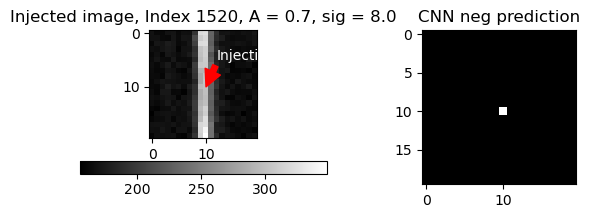

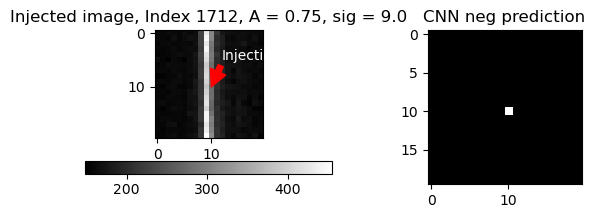

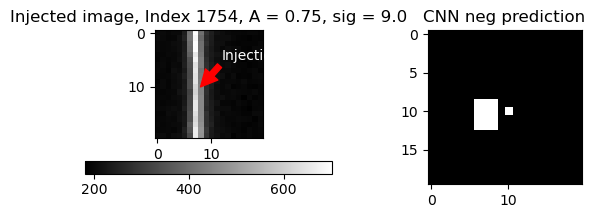

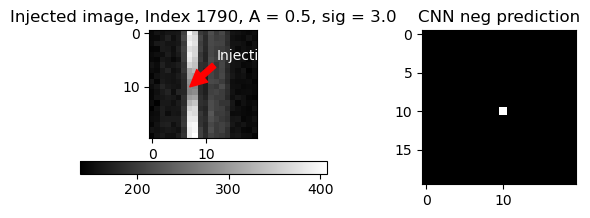

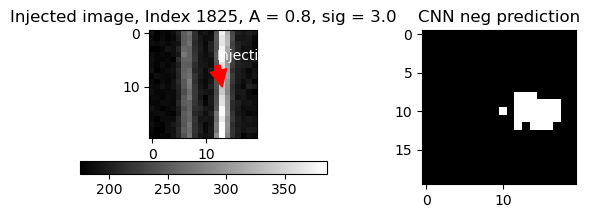

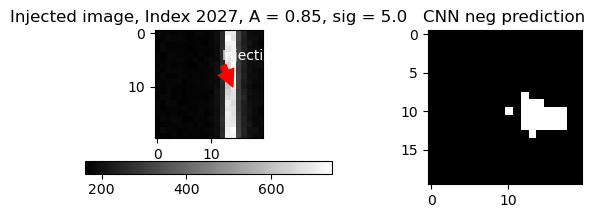

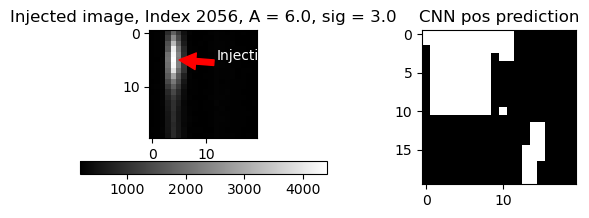

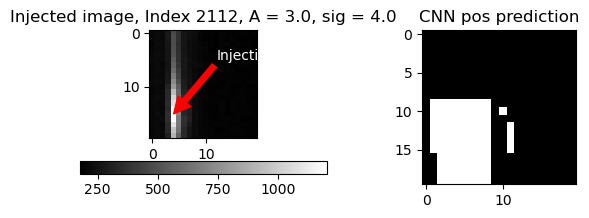

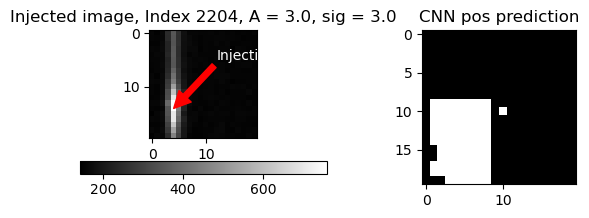

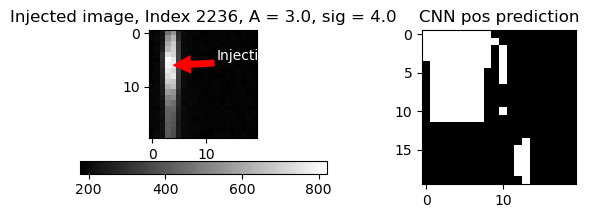

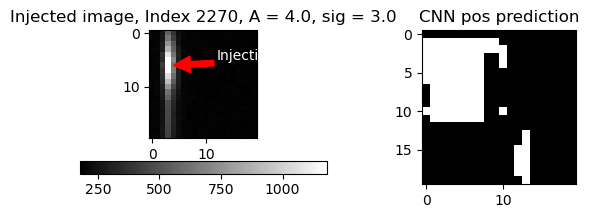

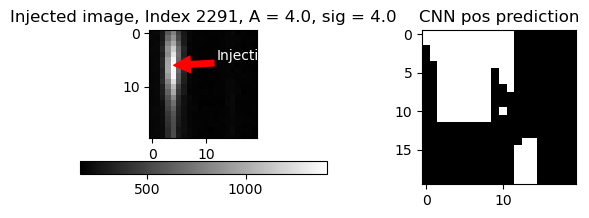

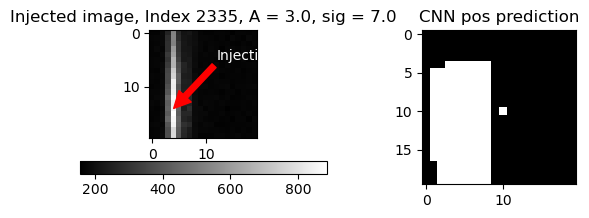

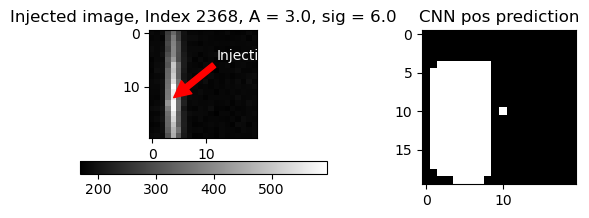

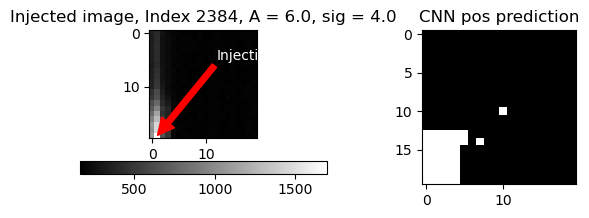

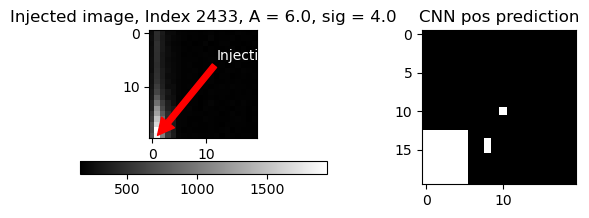

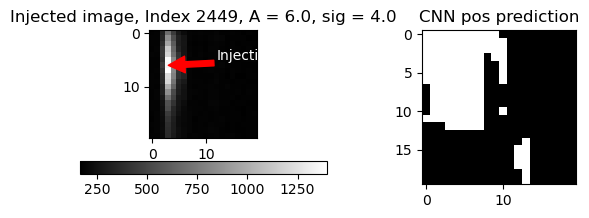

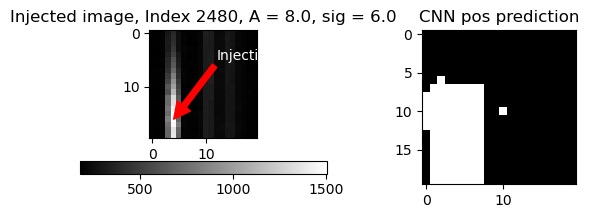

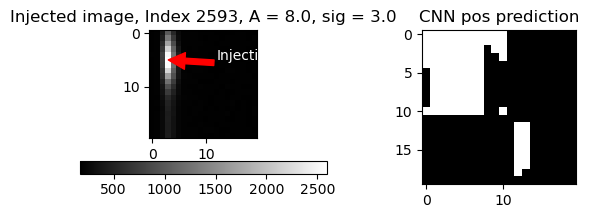

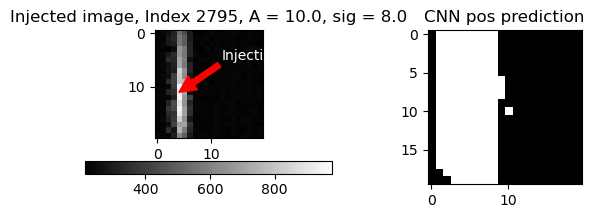

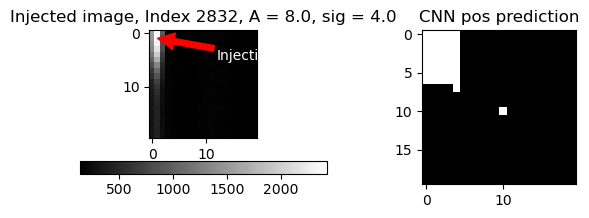

In [53]:
for index in df_eff_nodups[df_eff_nodups['detection_size']==1].index:
    rff.inspect_stamp_and_map(df_eff_nodups[df_eff_nodups['detection_size']==1],index, posneg=df_eff_nodups[df_eff_nodups['detection_size']==1].loc[index,"type"])

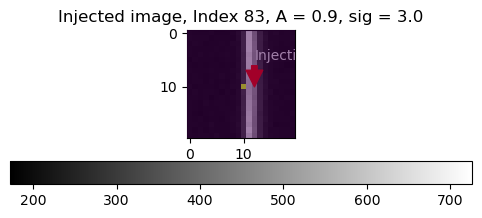

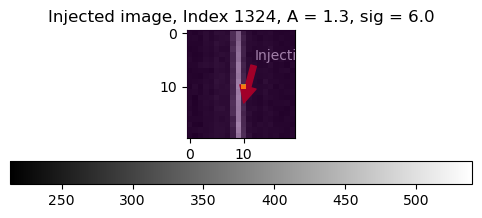

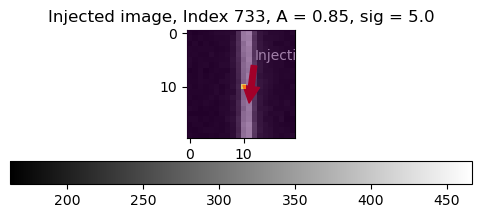

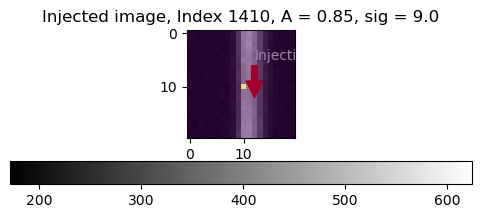

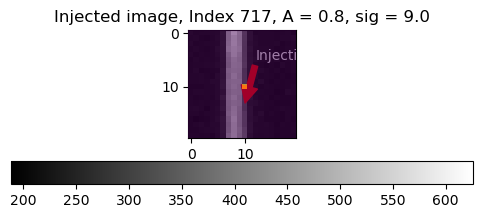

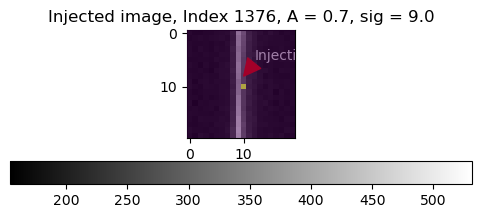

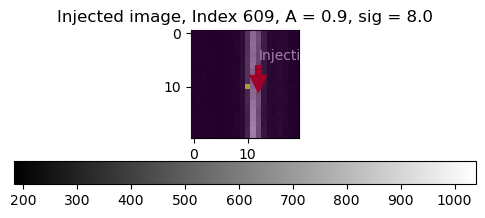

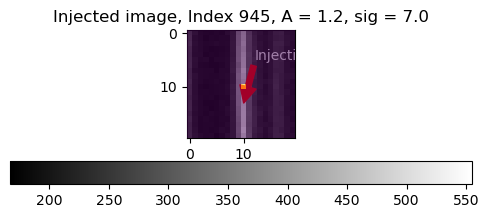

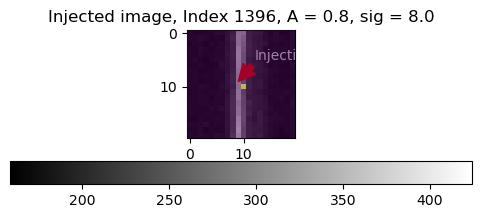

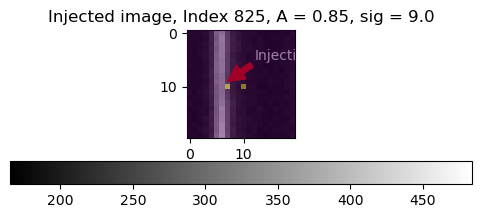

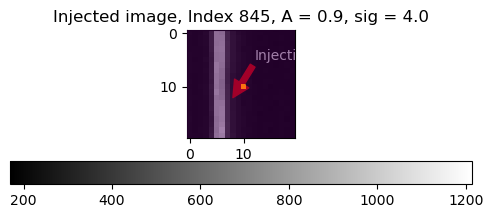

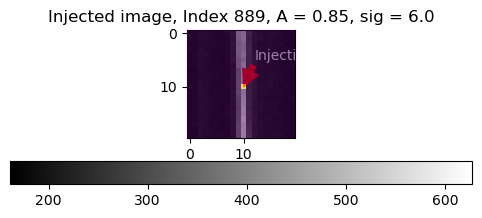

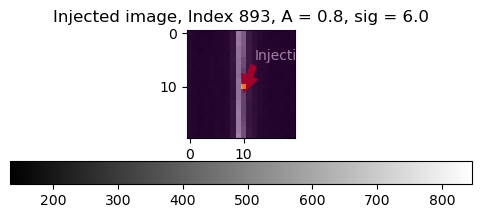

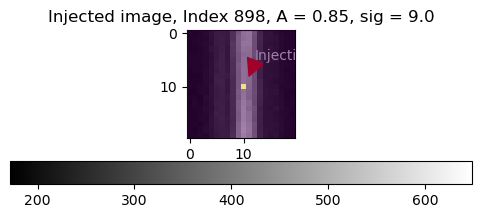

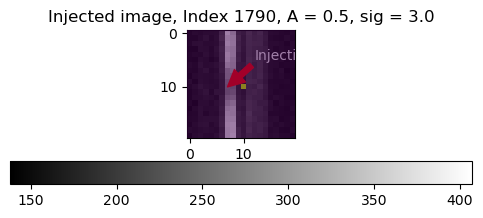

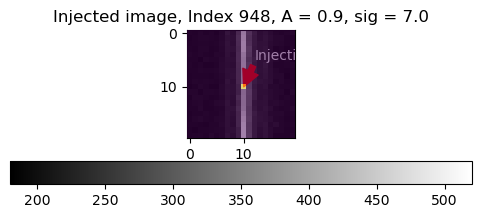

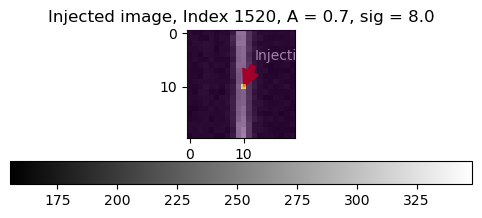

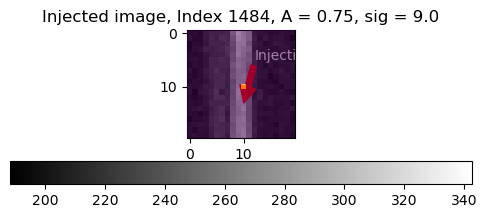

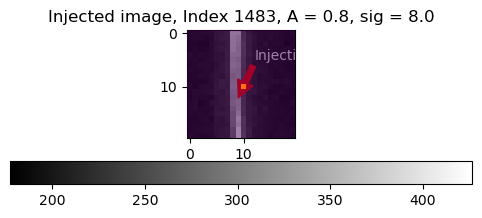

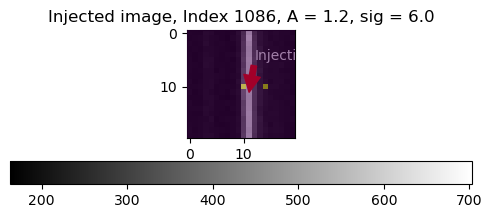

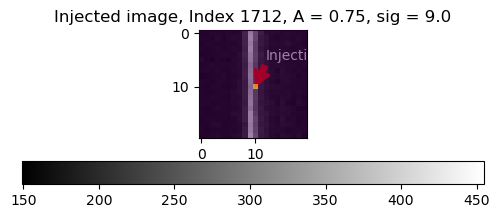

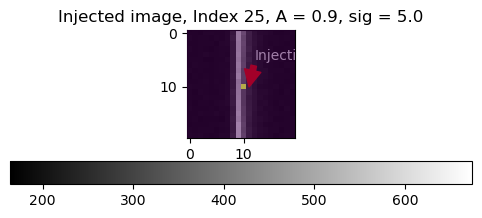

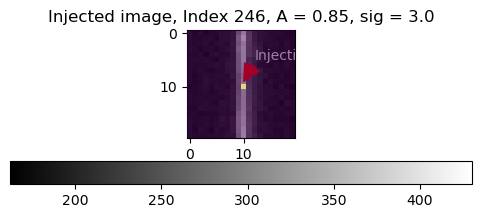

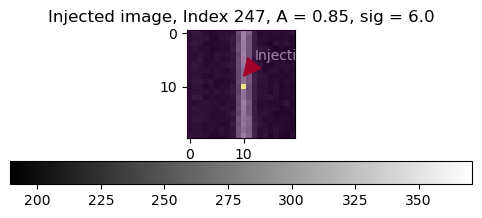

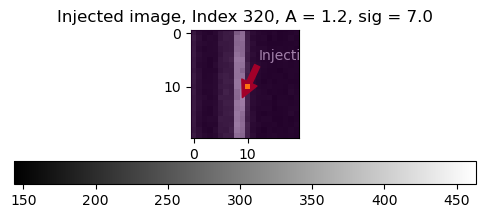

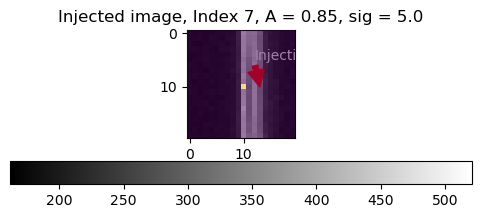

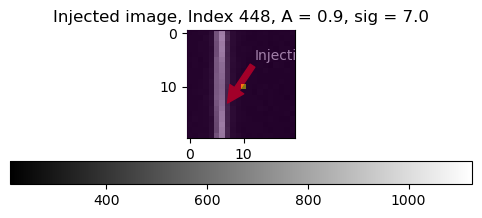

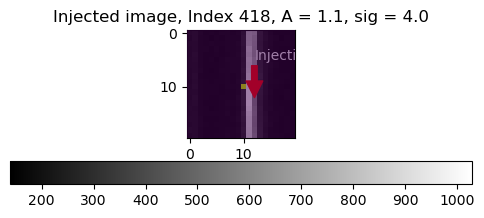

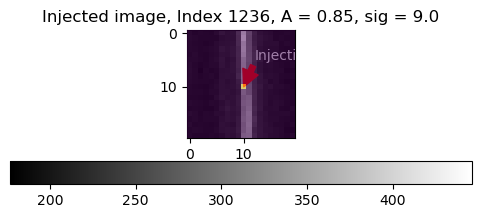

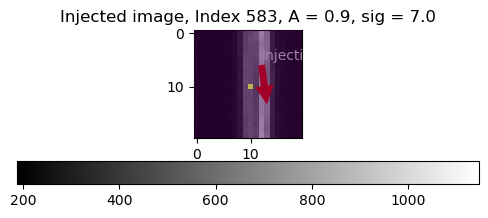

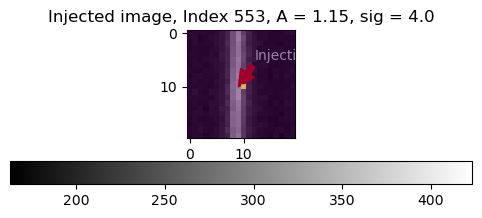

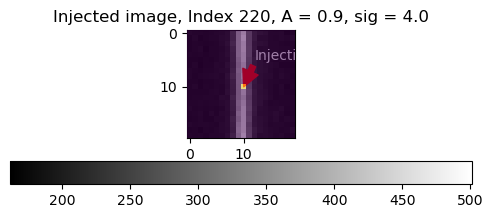

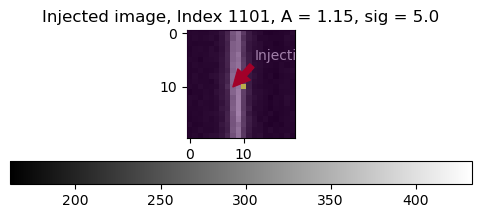

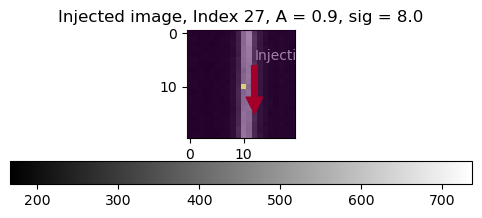

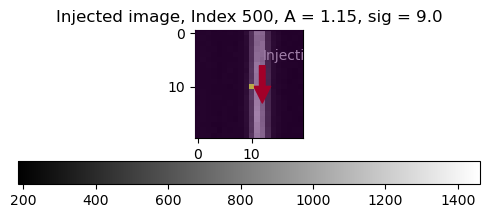

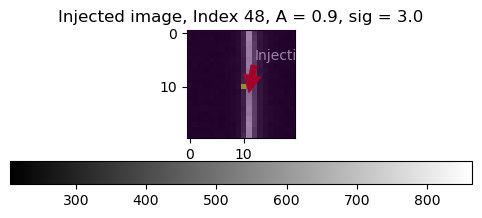

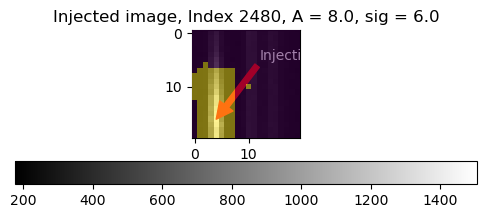

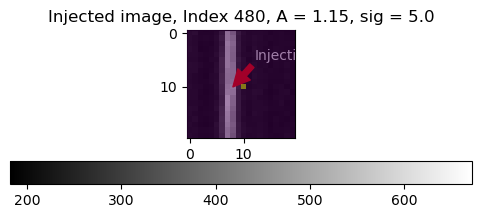

In [75]:
for index in df_eff_nodups_ds[df_eff_nodups_ds['detection_size']==1].index:
    stamp_over_map(df_eff_nodups_ds[df_eff_nodups_ds['detection_size']==1],index, posneg=df_eff_nodups_ds[df_eff_nodups_ds['detection_size']==1].loc[index,"type"])

In [74]:
def stamp_over_map(df, index, posneg, size=10, column=None, nn_or_imp="nn", thr=True, star=False):
    '''
    for efficiency data
    '''
    wid = 10
    if column!=None:
        index = df[df[column]==index].index[0]
    if posneg=="pos":
        extension = "_1_implanted_pos.npy"
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/images/'
        ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/predsarrays/"

    elif posneg=="neg":
        extension = "_1_implanted_neg.npy"
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/images/'
        ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/predsarrays/"


    fig, ax = plt.subplots(1, 1, figsize=(7,2))

    fname = df.loc[index]["filename"] + extension
    # print(df.iloc[index]["filename"])
    if nn_or_imp == "nn":
        row = int(df.loc[index]["row_from_nn"])+wid
        col = int(df.loc[index]["col_from_nn"])+wid
    elif nn_or_imp == "imp":
        row = int(df.loc[index]["col_from_implant"])
        col = int(df.loc[index]["row_from_implant"])
    path = fpath + fname
    array = np.load(path)
    imj = ax.imshow(
                
                    array[
                        row - size : row + size ,
                        col  - size : col  + size,
                    ]
                
                )
    nrow, ncol = array.shape
    if posneg =="pos":
        pfile = df.loc[index]["filename"]+"_extraction_predsarray_pos_predsarray.npy"
        predsarray = np.load(ppath+pfile)
        pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    elif posneg=="neg":
        pfile = df.loc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
        predsarray = np.load(ppath+pfile)
        pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    if thr:
        ax.imshow(
        
                    pimg[
                        col - size  - wid : col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ].T>.9999
                , alpha=.5, zorder=10, cmap='viridis')
#     else:
#         ax[0].imshow(
        
#                     pimg[
#                         col - size  - wid: col + size - wid,
#                         row  - size - wid: row  + size - wid,
#                     ].T
#                 )
#         ax[2].imshow(
        
#                     pimg[
#                         col - size  - wid: col + size - wid,
#                         row  - size - wid : row  + size - wid,
#                     ].T>.9999
#                 )
#         ax[2].set_title("CNN Thresholded")
    if star==True:
                    starpos = df.loc[index]['closest_x']
                    ax[0].scatter(starpos- (col - size  + wid), 10)
#     pfile_pos = df.iloc[index]["filename"]+"_extraction_predsarray_pos_predsarray.npy"
#     predsarray_pos = np.load(ppath+pfile_pos)
#     pimg_pos = predsarray_pos[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     pfile_neg = df.iloc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
#     predsarray_neg = np.load(ppath+pfile_neg)
#     pimg_neg = predsarray_neg[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     ax[1].imshow(
        
#                     pimg_neg[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 )
#     ax[2].imshow(pimg_pos[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 )            
    ax.annotate(
    "Injection",
    xy=(  df["row_from_implant"].loc[index]-col+size,df["col_from_implant"].loc[index]-row+size),
    xytext=(size+3*size/4, size/2),  
    arrowprops=dict(
        facecolor="red",
        edgecolor="red",
        # shrink=1.0,
        # headlength=5,
        # headwidth=3,
    ),
    color="white",
    fontsize=10,
    ha="center",
    # va="top",
    rotation=0,
    zorder=5,
)
    ax.set_title("Injected image, Index "+str(index)+ ", A = "+str(df["A_from_implant"].loc[index])+", sig = "+str(df["sig_from_implant"].loc[index]))
    # ax[1].set_title("CNN "+str(posneg)+" prediction")
    # ax[2].set_title("CNN pos prediction")
    # print(df["row_from_implant"].iloc[index], col, df["col_from_implant"].iloc[index], row)
    fig.colorbar(imj, orientation='horizontal')
    plt.show()

In [80]:
df_eff_nodups[np.abs(df_eff_nodups['Diff'])>10].iloc[0]

Unnamed: 0.4                                                          1282
Unnamed: 0.3                                                          1282
Unnamed: 0.2                                                          1282
Unnamed: 0.1                                                          1321
Unnamed: 0                                                            4080
filename                          ztf_20221020138241_000686_zi_c08_x_0014.
detection_size                                                          16
type                                                                   neg
row_from_nn                                                      1057.1875
col_from_nn                                                         2975.0
row_from_implant                                                    2985.0
col_from_implant                                                    1067.0
A_from_implant                                                         0.8
sig_from_implant         

In [15]:
df_inference.iloc[0]

Unnamed: 0.9                                                                 0
Unnamed: 0.8                                                                 0
Unnamed: 0.7                                                                 0
Unnamed: 0.6                                                                 0
Unnamed: 0.5                                                                 0
Unnamed: 0.4                                                                 0
Unnamed: 0.3                                                                 0
Unnamed: 0.2                                                                 0
Unnamed: 0.1                                                                 0
Unnamed: 0                                                                   0
filename                              ztf_20221020297847_000449_zr_c15_x_0006.
quad                                                                         4
type                                                

In [37]:
df_nodup = df_inf_nodups_again[df_inf_nodups_again['is_smaller_dup']==0]

In [38]:
df_nosat = df_nodup[df_nodup['satellite_flag']==0]

In [39]:
df_noone = df_nosat[df_nosat['detection_size']>1]

In [40]:
df_nosob = df_noone[df_noone['sobel_norm_stdv_rat']>3]

In [43]:
df_list = [df_inf_nodups_again, df_nodup, df_nosat, df_noone, df_nosob]

In [44]:
for df in df_list:
    print(len(df))


894775
564547
564513
511880
510945


In [29]:
df_nosob.sort_values('snr_local_new',ascending=False)[:100]['snr_local_new']

685822    11.176349
55624      8.231839
591644     7.954380
725664     7.729711
779046     7.488108
            ...    
667680     4.791449
403552     4.767212
757939     4.766905
83858      4.763518
878147     4.714519
Name: snr_local_new, Length: 100, dtype: float64

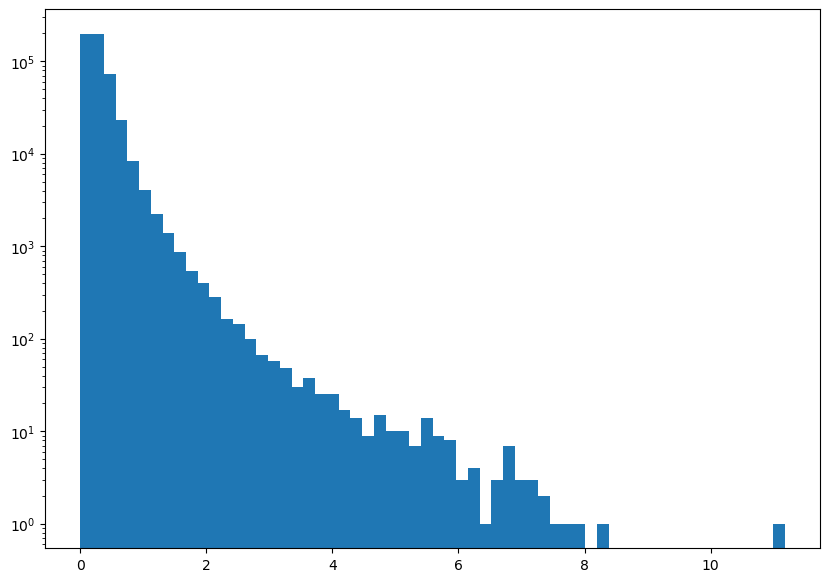

In [30]:
plt.hist(df_nosob['snr_local_new'], bins=60)
plt.yscale('log')

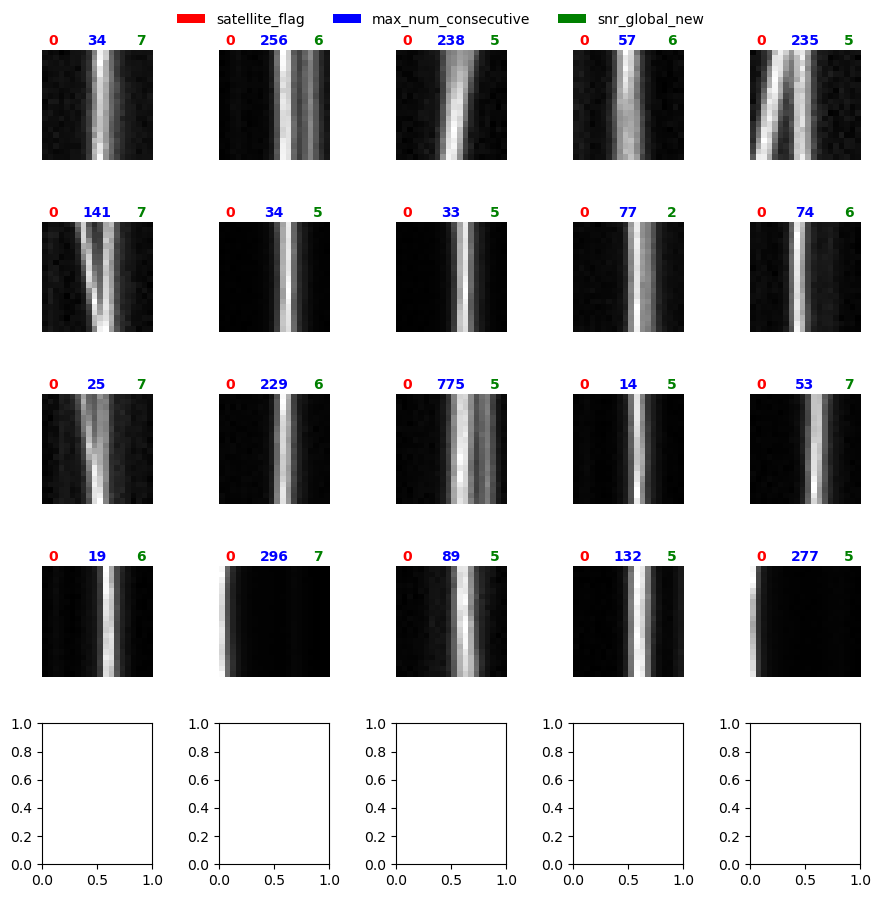

In [50]:
rff.inspect_df_w_stamp_color(df_nosob[df_nosob['Diff']<5].sort_values('snr_local_new',ascending=False)[:20], titlecol=['satellite_flag','max_num_consecutive','snr_global_new' ])

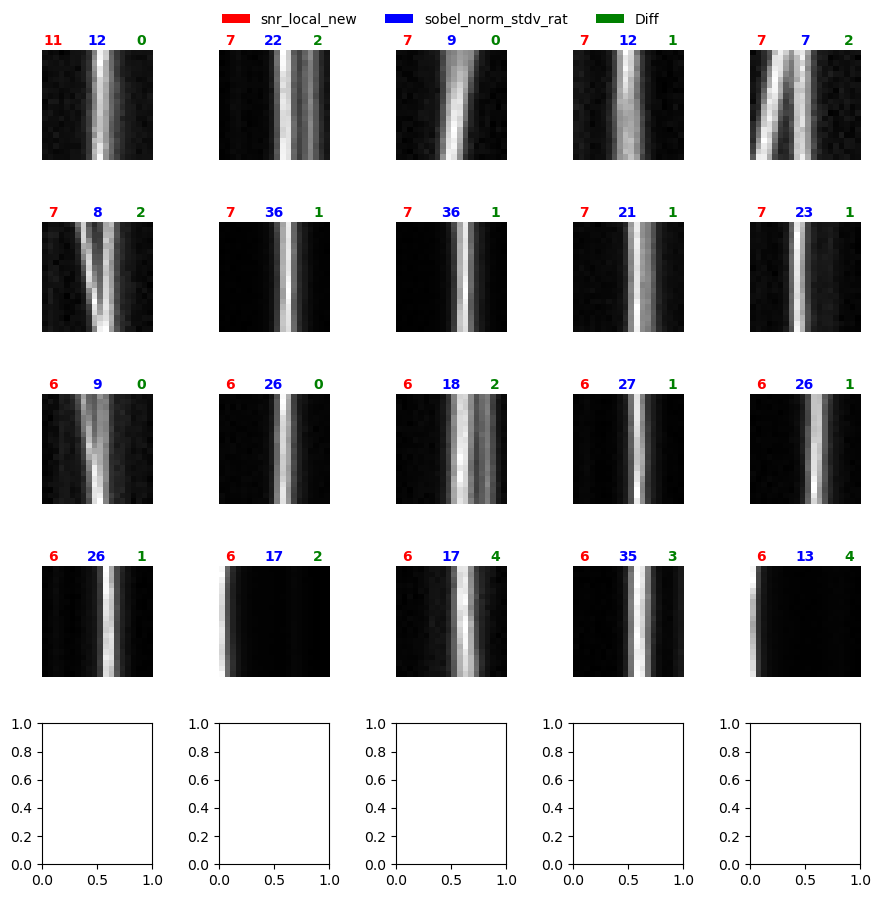

In [33]:
rff.inspect_df_w_stamp_color(df_nosob[df_nosob['Diff']<5].sort_values('snr_local_new',ascending=False)[:20], titlecol=['snr_local_new','sobel_norm_stdv_rat','Diff' ])

In [47]:
for df in df_list:
    print(len(df))

894775
564547
564513
511880
510945


In [ ]:
#so if we do all the cuts...


for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups[df_eff_nodups[quant]<option])/len(df_eff_nodups):.1f} % with cutoff < {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups[df_inf_nodups[quant2]<option])/len(df_inf_nodups):.1f}% from {len(df_inf_nodups)} to {len(df_inf_nodups[df_inf_nodups[quant2]>=option])}.")


In [53]:
!pip install corner

In [8]:
import corner




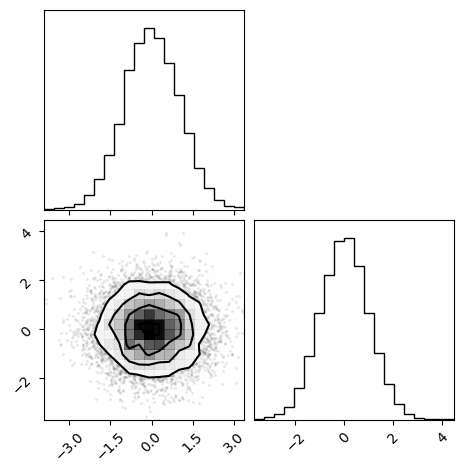

In [55]:
ndim, nsamples = 2, 10000
np.random.seed(42)
samples = np.random.randn(ndim * nsamples).reshape([nsamples, ndim])
figure = corner.corner(samples)

In [71]:
np.sum(df_nodup['is_smaller_dup'])

0.0

In [17]:
df_nodup.head()

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,num_in_file_new,num_consecutive_up_new,num_consecutive_down_new,possible_up_indices_new,possible_down_indices_new,max_num_consecutive_new,sat_flag,sat_neighbor,log_detection_size,log_snr
0,0,0,0,0,0,0,0,0,0,0,...,233.0,0.0,0.0,[],[],0.0,0.0,0.0,1.146128,-1.273339
1,2,2,2,2,2,2,2,2,2,2,...,233.0,0.0,0.0,[],[],0.0,0.0,0.0,1.176091,-0.842616
2,4,4,4,4,4,4,4,4,4,4,...,233.0,2.0,79.0,[0 2],[ 7 11 15 17 20 25 28 32 35 38 41 ...,1.0,0.0,0.0,0.301030,-0.882224
3,7,7,7,7,7,7,7,7,7,7,...,233.0,0.0,0.0,[],[],0.0,0.0,0.0,1.146128,-1.022078
4,9,9,9,9,9,9,9,9,9,9,...,233.0,3.0,78.0,[0 2 7],[ 11 15 17 20 25 28 32 35 38 41 43 ...,1.0,0.0,0.0,0.903090,-1.229741


In [4]:
df_nodup = df_inf[df_inf['is_smaller_dup']==0]

In [11]:
df_plot = df_nodup[df_nodup['detection_size']>1]
df_plot = df_plot[df_plot['sobel_norm_stdv_rat']>3]

In [18]:
plotlist = ['snr_local_new',
                                 'detection_size', 
            'log_snr',
            'log_detection_size',
                                 'Diff',
                                 'num_in_file',
                                 # 'num_in_file_in_star', 
                                 'sobel_norm_stdv_rat',
                                 'sobel_norm_diffmax',
                                 'max_num_consecutive_new',
                                ]

In [10]:
df_nodup['log_detection_size'] = np.log10(df_nodup['detection_size'])
df_nodup['log_snr'] = np.log10(df_nodup['snr_local_new'])

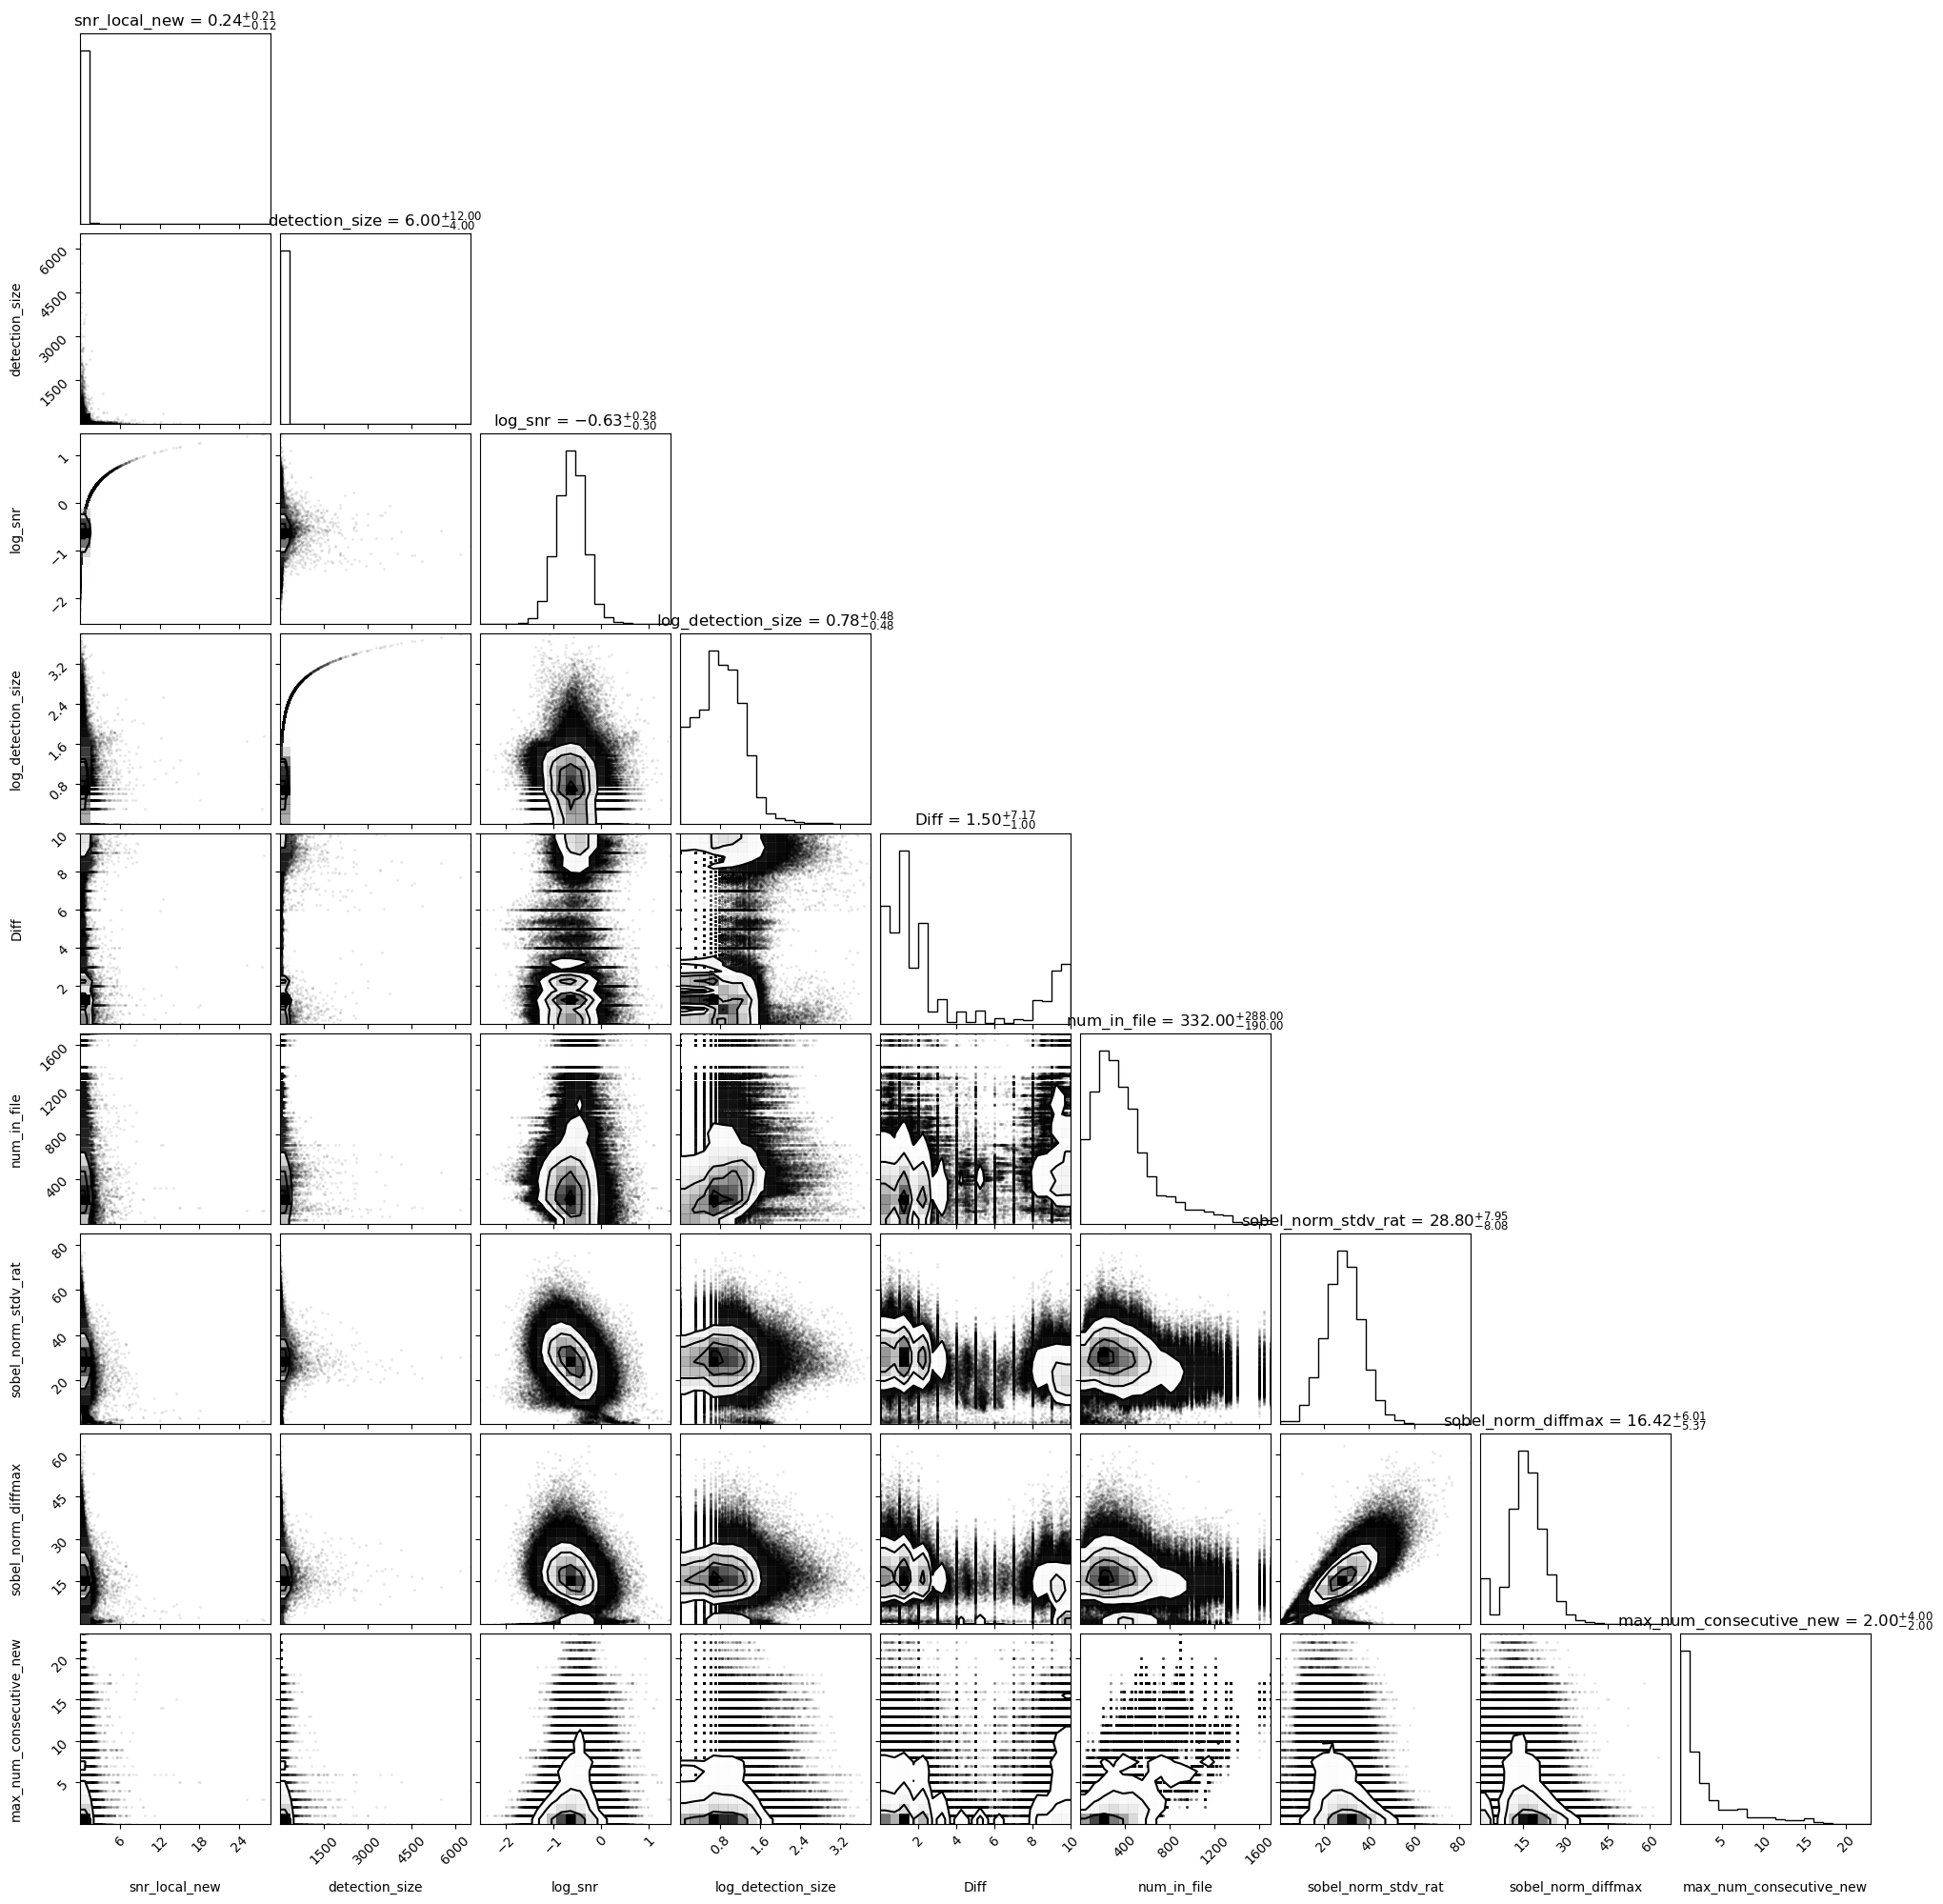

In [19]:
figure = corner.corner(df_nodup[plotlist],
                       labels=plotlist,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

In [77]:
np.min(df_plot['detection_size'])

2.0

In [80]:
df_plot['log_detection_size'] = np.log10(df_plot['detection_size'])
df_plot['log_snr'] = np.log10(df_plot['snr_local_new'])

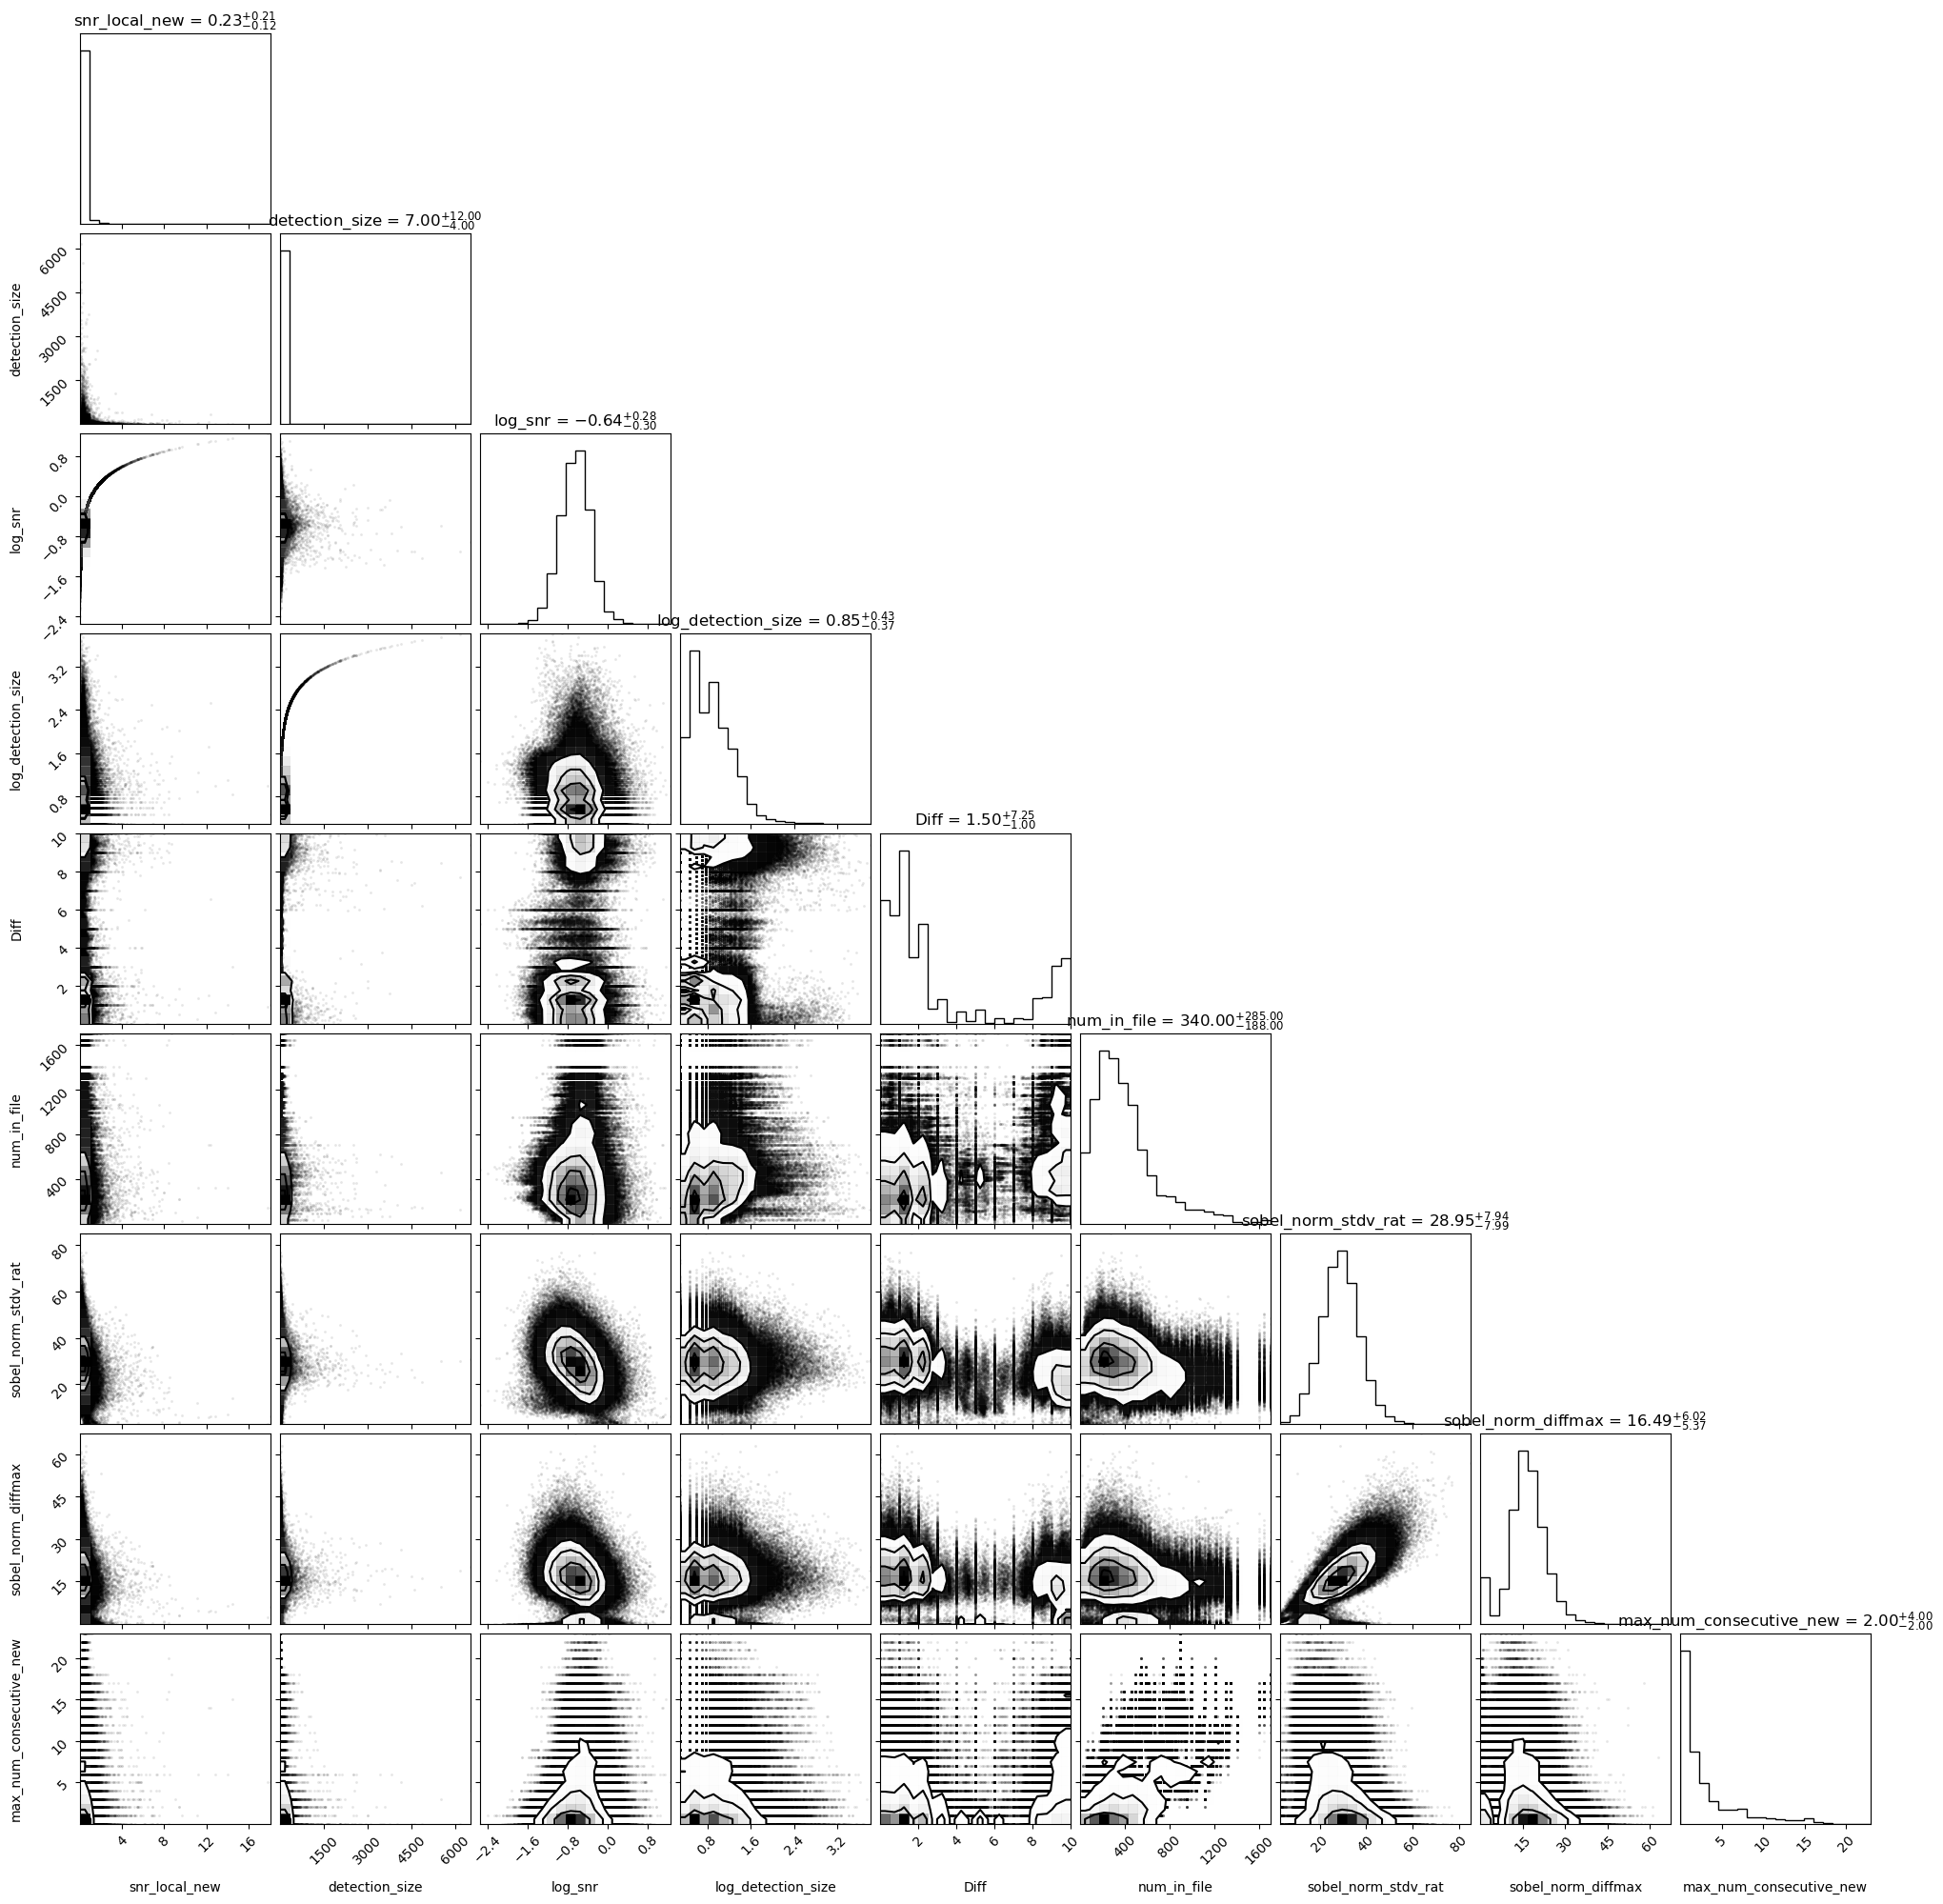

In [20]:
figure = corner.corner(df_plot[plotlist],
                       labels=plotlist,
    # labels=[
    #     r"$snr_local_new$",
    #     r"$detection_size$",
    #     r"$Diff$",
    #     r"$\Gamma \, [\mathrm{parsec}]$",
    # ],
    # quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},)

The efficiency drops by 0.1 % with cutoff < 2.7.
The number of candidates reduces by 0.2% from 564547 to 563641.
The efficiency drops by 0.4 % with cutoff < 3.
The number of candidates reduces by 0.2% from 564547 to 563535.
The efficiency drops by 5.7 % with cutoff < 5.
The number of candidates reduces by 0.3% from 564547 to 562950.
The efficiency drops by 17.4 % with cutoff < 8.
The number of candidates reduces by 0.5% from 564547 to 561861.


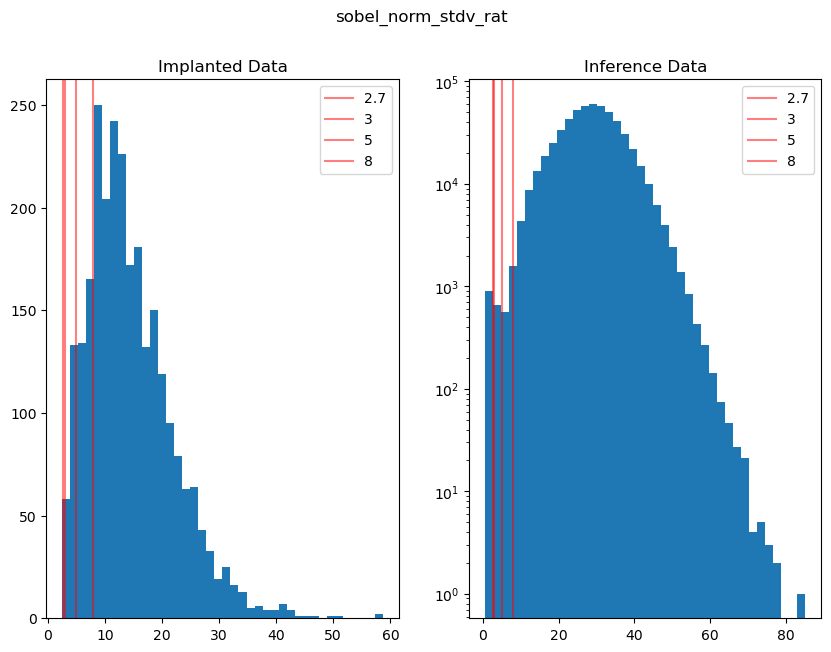

In [87]:


quant = "sobel_norm_stdv_rat"
quant2 = "sobel_norm_stdv_rat"
cutoff_options = [2.7,3,5,8]
bins = 40
fig, ax = plt.subplots(1,2)
ax[0].hist(df_eff_nodups[quant], bins=bins)
ax[1].hist(df_inf_nodups[quant2], bins=bins)
ax[0].set_title("Implanted Data")
ax[1].set_title("Inference Data")
for option in cutoff_options:
    print(f"The efficiency drops by {100*len(df_eff_nodups[df_eff_nodups[quant]<option])/len(df_eff_nodups):.1f} % with cutoff < {option}.")
    print(f"The number of candidates reduces by {100*len(df_inf_nodups[df_inf_nodups[quant2]<option])/len(df_inf_nodups):.1f}% from {len(df_inf_nodups)} to {len(df_inf_nodups[df_inf_nodups[quant2]>=option])}.")
    for axis in ax:
        axis.axvline(option, label=option,c="r", alpha=.5)
        axis.legend()
        
fig.suptitle(quant)
ax[1].set_yscale("log")

In [6]:
df_inf = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_inf_sats")

In [45]:
df_inf = rff.add_num_in_file_in_star(df_inf)

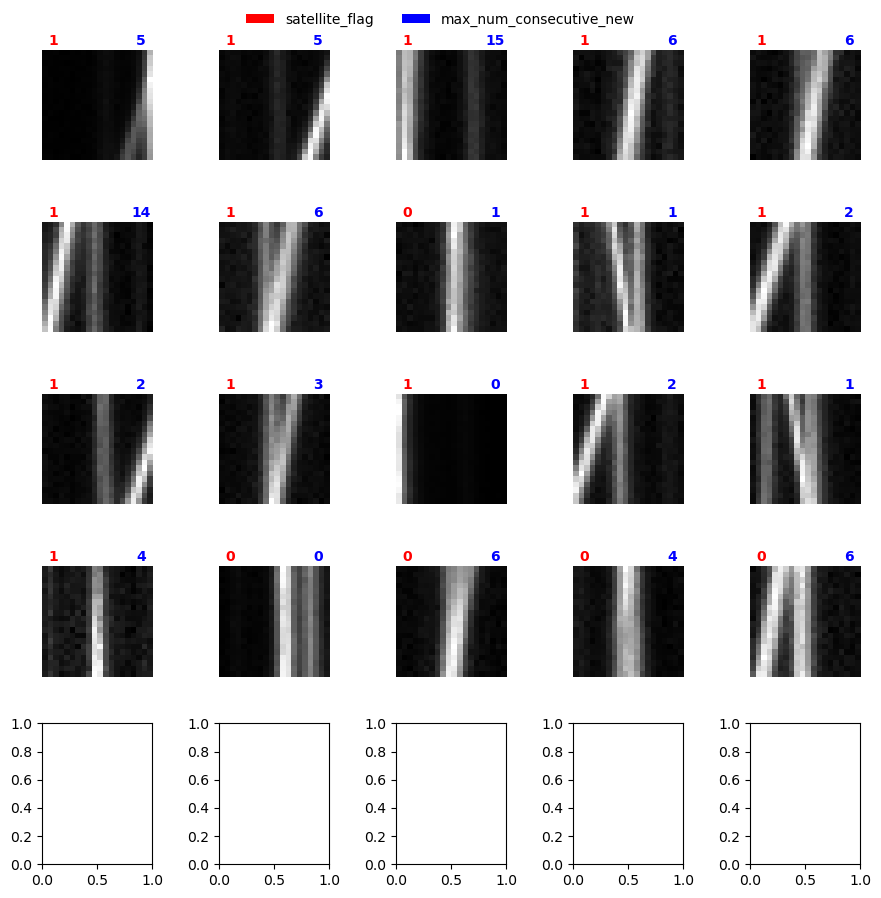

In [22]:

rff.inspect_df_w_stamp_color(df_plot[df_plot['Diff']<5].sort_values('snr_local_new',ascending=False)[:20], titlecol=['satellite_flag','max_num_consecutive_new'])

In [6]:
df_eff = rff.find_dups(df_eff)

In [7]:
df_eff = rff.add_num_in_file_in_star(df_eff)

In [33]:
df_eff_nodups = df_eff_nodups[df_eff_nodups['is_smaller_dup']==0]

In [34]:
df_eff_sat = rff.add_num_consecutive(df_eff_nodups)

no df_larger


In [36]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [37]:
df_eff_sat = rff.add_sat_and_proximity(df_eff_sat, eff=True)

In [40]:
np.sum(df_eff_sat['sat_flag']==True)

221

In [46]:
np.sum(df_eff_sat['sat_flag']==True)/len(df_eff_sat)

0.08339622641509434

In [43]:
rff.inspect_df_w_stamp_color?

Signature:
rff.inspect_df_w_stamp_color(
    df,
    imgsize=10,
    star=False,
    clim=None,
    plot='stamp',
    norm=False,
    titlecol=[],
    twodec=False,
)
Docstring:
plots the stamps corresponding to detections in a dataframe
no limit, so put in df[:100] or something probably to save time
File:      ~/rwe/review_findings_functions.py
Type:      function

KeyError: 'stamp'

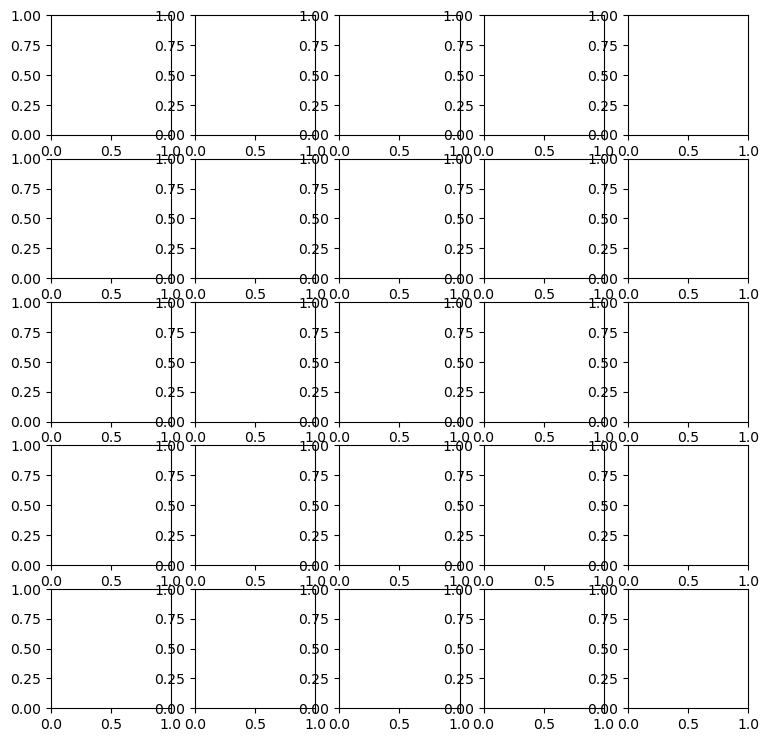

In [42]:

rff.inspect_df_w_stamp_color(df_eff_sat[df_eff_sat['sat_flag']==True].sort_values('snr_local',ascending=False)[:20], titlecol=['satellite_flag','max_num_consecutive_new'])

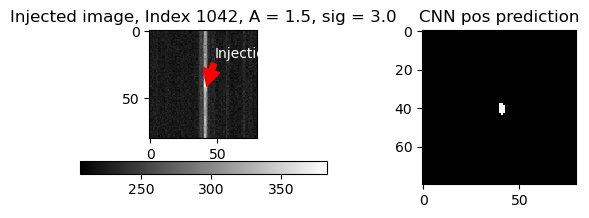

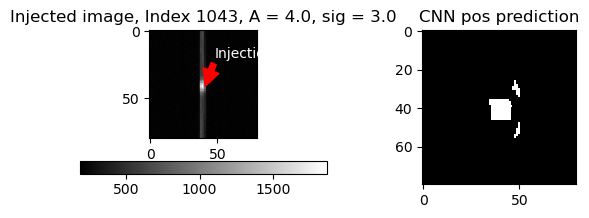

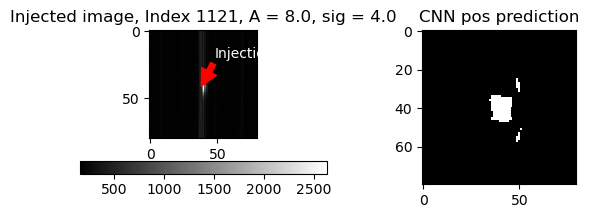

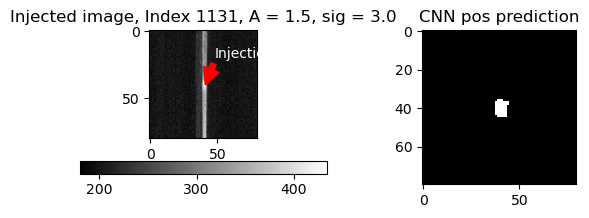

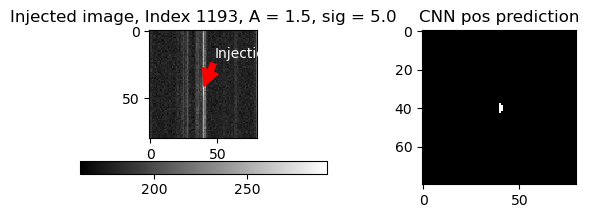

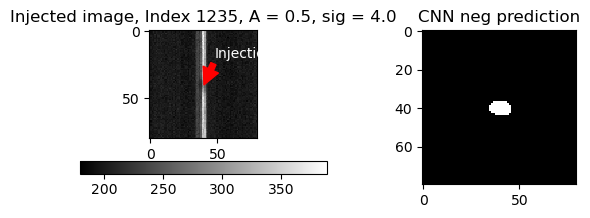

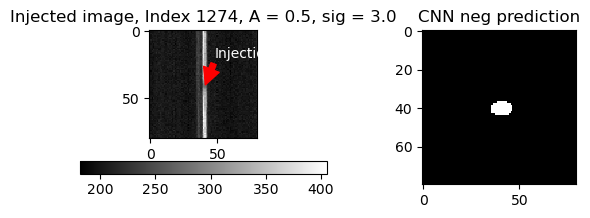

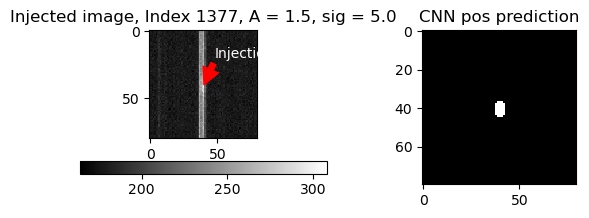

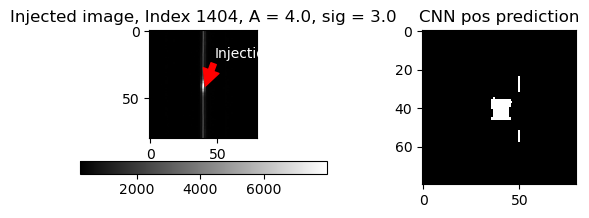

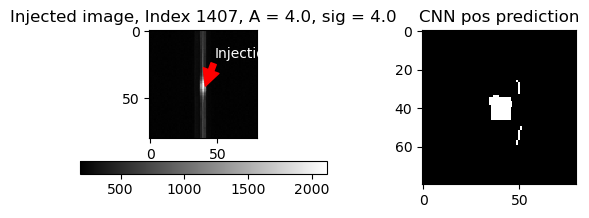

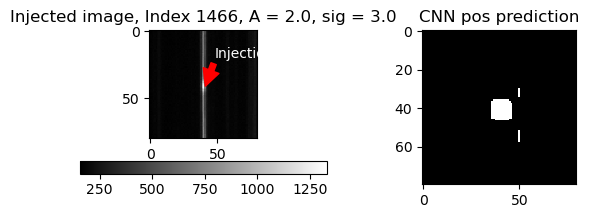

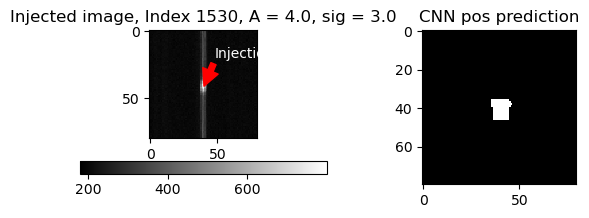

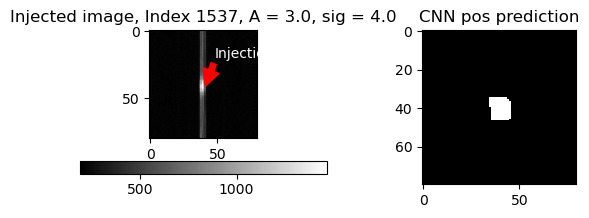

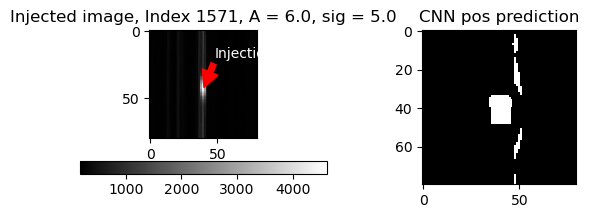

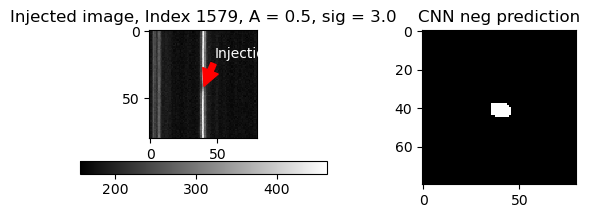

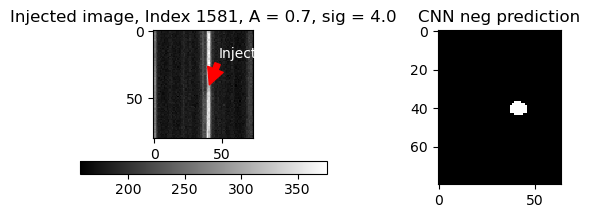

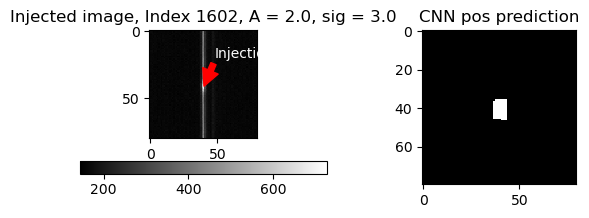

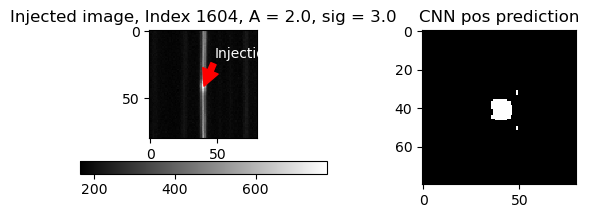

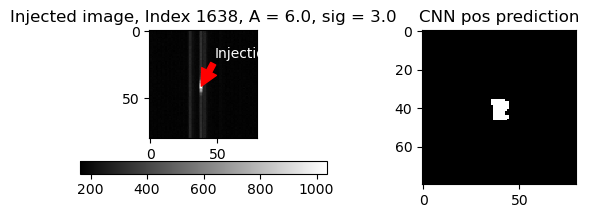

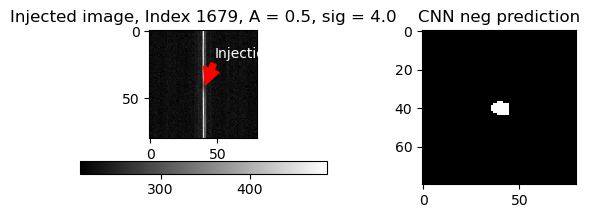

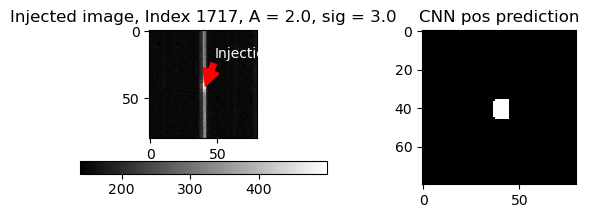

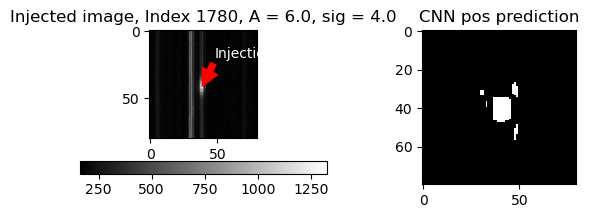

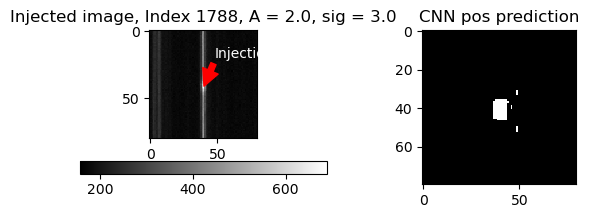

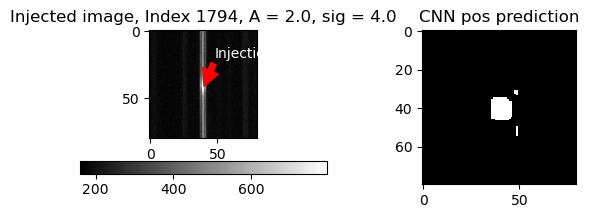

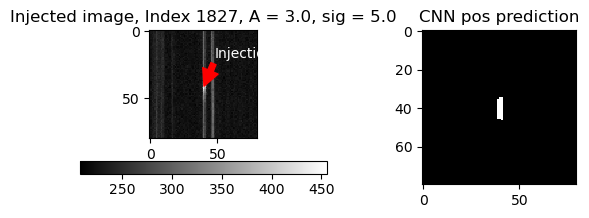

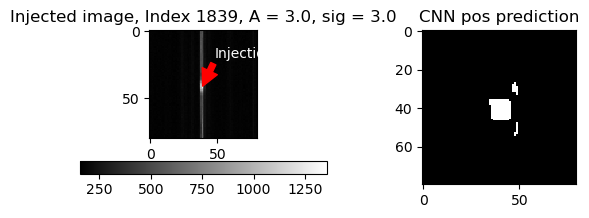

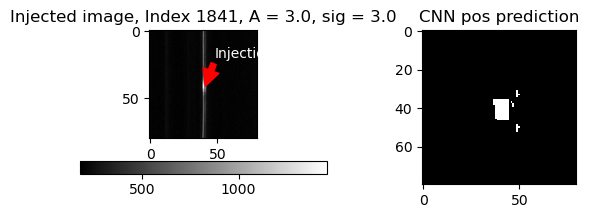

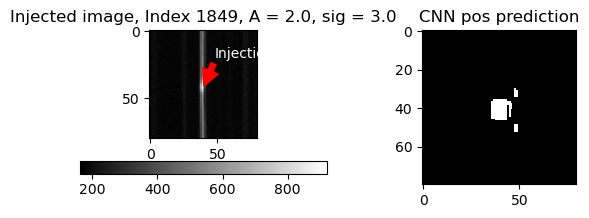

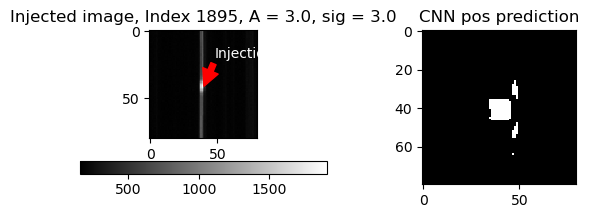

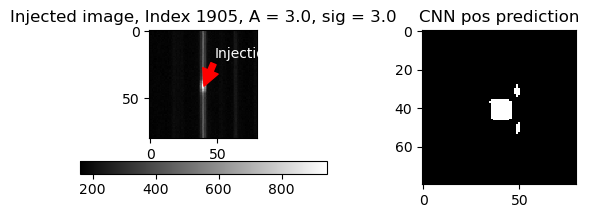

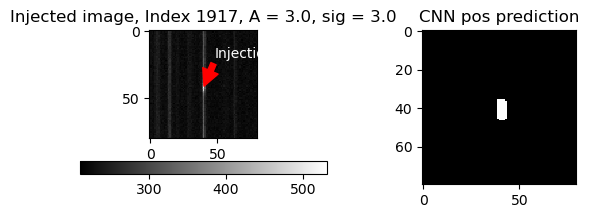

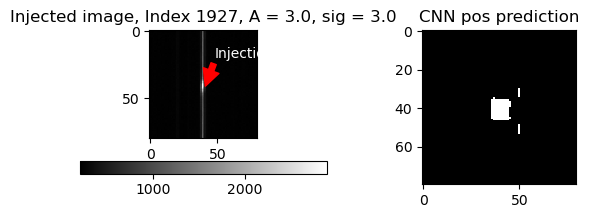

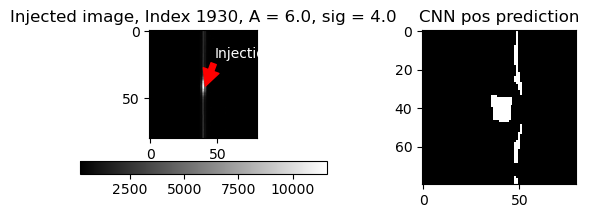

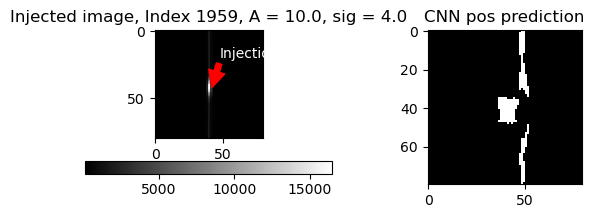

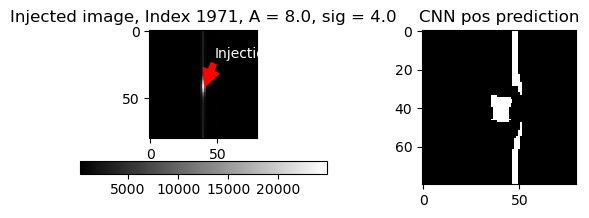

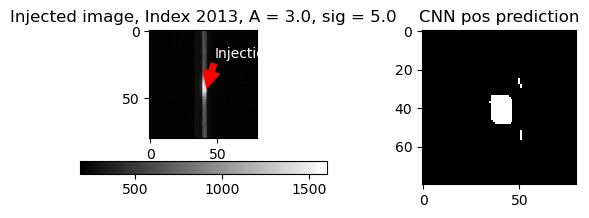

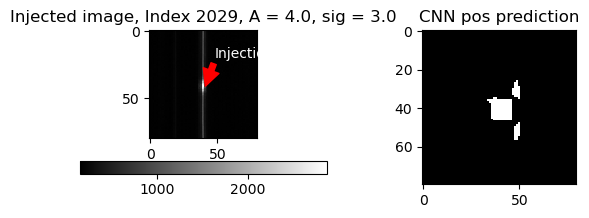

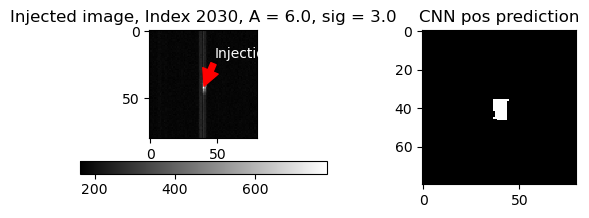

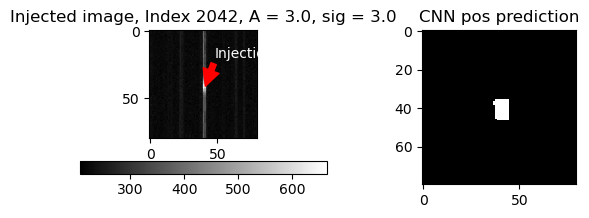

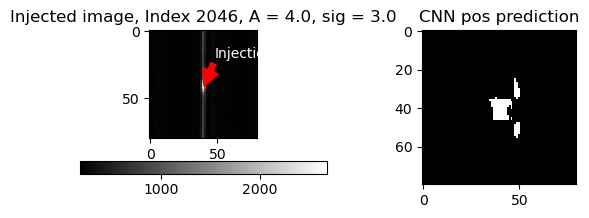

In [45]:
for index in df_eff_sat[df_eff_sat['sat_flag']==True].index[:40]:
    rff.inspect_stamp_and_map(df_eff_sat, index, eff=True, size=40)

In [8]:
df_maybe = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_inf_dups")

In [9]:
df_maybe = rff.add_num_in_file_in_star(df_maybe)

In [10]:
def print_statement(smaller_eff,bigger_eff, smaller_inf, bigger_inf):
    print(f"The efficiency drops by {100*(len(bigger_eff)-len(smaller_eff))/len(bigger_eff):.1f} %.")
    print(f"The number of candidates reduces by {100*(len(bigger_inf)-len(smaller_inf))/len(bigger_inf):.1f}% from {len(bigger_inf)} to {len(smaller_inf)}.")


In [17]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [28]:
#so if we do all the cuts...



def get_real_cands_print(df_inf, df_eff, detsizelim=1, usesatflag=True, usesatneighbor=True, crstdvlim=3, diff=5, maxnuminstar=20,snr_thresh=1):
    
    df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/df_implants_pos")
    df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")
    base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"
    df_pos = pd.read_csv(base_path+"df_detections_pos_only")
    df_neg = pd.read_csv(base_path+"df_detections_neg_only")
    both = pd.concat([df_neg,df_pos], ignore_index=True)
    both = rff.reduce_edges(both, 15)
    
    print(f"CNN efficiency: Found {len(rmdups(both, eff=True, size=True))} out of {len(df_implants_pos)+len(df_implants_neg)} transients, or {100*(len(rmdups(both, eff=True, size=True)))/(len(df_implants_pos)+len(df_implants_neg)):.1f}%")

    matched = rff.match_stars_eff(both)
    matched = matched[matched["Diff"]<10]
    
    print(f"Matching to within {diff} of known stars (compared to within 10):")
    inf00 = df_inf[df_inf["Diff"]<diff]
    eff00 = rmdups(matched[np.abs(matched["Diff"])<diff], eff=True, size=True)
    if 1==1:
        return eff00
    
    
    print_statement(eff00, both, inf00, df_inf)    
    
    print(f"\n Restricting to stars with < {maxnuminstar} total candidates (just a guess):")
    inf0 = inf00[inf00["num_in_file_in_star"]<maxnuminstar]
    eff0 = df_eff[df_eff["num_in_file_in_star"]<maxnuminstar]
    
    
    print_statement(eff0, eff00, inf0, inf00)
    
    
    print("\n Deduplication: ")
    inf = inf0[inf0["is_smaller_dup"]==0]
    eff = eff0[eff0["is_smaller_dup"]==0]
    
    
    print_statement(eff, rmdups(eff0, eff=True), inf0, inf)
    
    print(f"\n Detection size > : {detsizelim}")
    inf2 = inf[inf['detection_size']>detsizelim]
    eff2 = eff[eff['detection_size']>detsizelim]
    
    
    print_statement(eff2, eff, inf2, inf)
    

    print(f"\n Cosmic ray criterion with threshold: {crstdvlim}")
    inf3 = inf2[inf2['sobel_norm_stdv_rat']>crstdvlim]
    eff3 = eff2[eff2['sobel_norm_stdv_rat']>crstdvlim]
    
    
    print_statement(eff3, eff2, inf3, inf2)
    
    print("\nSatellite flag tbd should remove about 100 candidates")
    
    print(f"\n After all this, if we look at transient candidates with snr > {snr_thresh}...")
    
    inf4 = inf3[inf3['snr_local_new']>snr_thresh]
    eff4 = eff3[eff3['snr_local']>snr_thresh] 
    print_statement(eff4, eff3, inf4, inf3)
    

#     if maxnuminstar>0:
#         df = df[df['num_in_file_in_star']<maxnuminstar]
#     df = df[df['Diff']<=diff]
    # return df
                       #df = df[df[
    

In [29]:
ef00 = get_real_cands_print(df_maybe, df_eff)

Number of transient candidates reduced from 3018 to 3004.
CNN efficiency: Found 2693 out of 3594 transients, or 74.9%
Matching to within 5 of known stars (compared to within 10):


/tmp/ipykernel_22477/833891694.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.sort_values("detection_size", inplace=True)


In [33]:
np.max(ef00['Diff'])

4.978260869565247

In [35]:
np.min(df_eff["detection_size"])

1

In [25]:
get_real_cands_print(df_maybe, df_eff)

Number of transient candidates reduced from 3018 to 3004.
CNN efficiency: Found 2693 out of 3594 transients, or 74.9%
Matching to within 5 of known stars (compared to within 10):
The efficiency drops by 12.3 %.
The number of candidates reduces by 25.9% from 894775 to 662949.

 Restricting to stars with < 20 total candidates (just a guess):
The efficiency drops by -11.7 %.
The number of candidates reduces by 94.3% from 662949 to 37791.

 Deduplication: 
The efficiency drops by 0.1 %.
The number of candidates reduces by -11.9% from 33762 to 37791.

 Detection size > : 1
The efficiency drops by 1.4 %.
The number of candidates reduces by 29.7% from 33762 to 23720.

 Cosmic ray criterion with threshold: 3
The efficiency drops by 0.3 %.
The number of candidates reduces by 3.1% from 23720 to 22995.

Satellite flag tbd should remove about 100 candidates

 After all this, if we look at transient candidates with snr > 1...
The efficiency drops by 13.9 %.
The number of candidates reduces by 95.4%

/tmp/ipykernel_22477/833891694.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.sort_values("detection_size", inplace=True)


In [26]:
get_real_cands_print(df_maybe, df_eff, diff=8)

Number of transient candidates reduced from 3018 to 3004.
CNN efficiency: Found 2693 out of 3594 transients, or 74.9%
Matching to within 8 of known stars (compared to within 10):
The efficiency drops by 11.8 %.
The number of candidates reduces by 20.4% from 894775 to 712166.

 Restricting to stars with < 20 total candidates (just a guess):
The efficiency drops by -11.0 %.
The number of candidates reduces by 94.4% from 712166 to 39526.

 Deduplication: 
The efficiency drops by 0.1 %.
The number of candidates reduces by -12.8% from 35031 to 39526.

 Detection size > : 1
The efficiency drops by 1.4 %.
The number of candidates reduces by 29.8% from 35031 to 24575.

 Cosmic ray criterion with threshold: 3
The efficiency drops by 0.3 %.
The number of candidates reduces by 3.3% from 24575 to 23766.

Satellite flag tbd should remove about 100 candidates

 After all this, if we look at transient candidates with snr > 1...
The efficiency drops by 13.9 %.
The number of candidates reduces by 95.5%

/tmp/ipykernel_22477/833891694.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.sort_values("detection_size", inplace=True)


(array([161555.,  23093.,  36787.,  28788.,  59443., 384773., 166419.,
         21472.,   6513.,   5932.]),
 array([-10.,  -8.,  -6.,  -4.,  -2.,   0.,   2.,   4.,   6.,   8.,  10.]),
 <BarContainer object of 10 artists>)

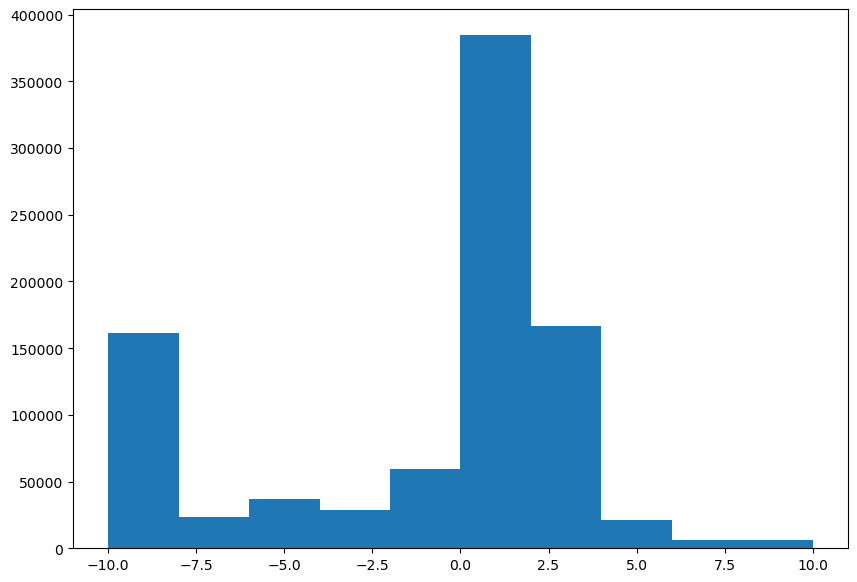

In [5]:
plt.hist(df_inference['closest_x']-(df_inference['col_from_nn']+10))